# Квантизация на Triton

*Triton 3.8, PyTorch 2.10, NVIDIA A100.*

# 1. Окружение

In [1]:
# !pip install -U triton tabulate matplotlib

In [14]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import triton
import triton.language as tl
from triton.language.extra import libdevice
from triton.testing import do_bench
from tabulate import tabulate

assert torch.cuda.is_available(), "семинар рассчитан на GPU"
DEVICE = torch.device("cuda")
torch.manual_seed(0)

sys.path.insert(0, os.path.abspath("bnbtriton/src"))
from bnbtriton.quantize_rowwise import quantize_rowwise as bnb_quantize_rowwise
from bnbtriton.dequantize_rowwise import dequantize_rowwise as bnb_dequantize_rowwise
from bnbtriton.int8_matmul_rowwise_dequantize import int8_matmul_rowwise_dequantize as bnb_int8_matmul

print(f"triton {triton.__version__} | torch {torch.__version__} | GPU: {torch.cuda.get_device_name()}")

triton 3.8.0 | torch 2.10.0+cu128 | GPU: NVIDIA A100-SXM4-80GB


In [15]:
def bench(variants: dict, baseline: str | None = None):
    for fn in variants.values():
        fn()                                   
    times = {name: do_bench(fn) for name, fn in variants.items()}
    base_name = baseline or next(iter(times))
    rows = [[name, f"{t:.3f}", f"×{times[base_name] / t:.2f}"] for name, t in times.items()]
    print(tabulate(rows, headers=["вариант", "время, ms", f"ускорение vs «{base_name}»"], tablefmt="github"))


def rel_err(x, x_hat):
    return ((x.float() - x_hat.float()).norm() / x.float().norm()).item()

## Вспомним прошлую лекцию

Квантизацию удобно понимать через интегральную сумму. Возьмём криволинейную трапецию — область под кривой $f(x)$ на отрезке $[x_{\min},\ x_{\max}]$. Её площадь $S$ и хотим посчитать.

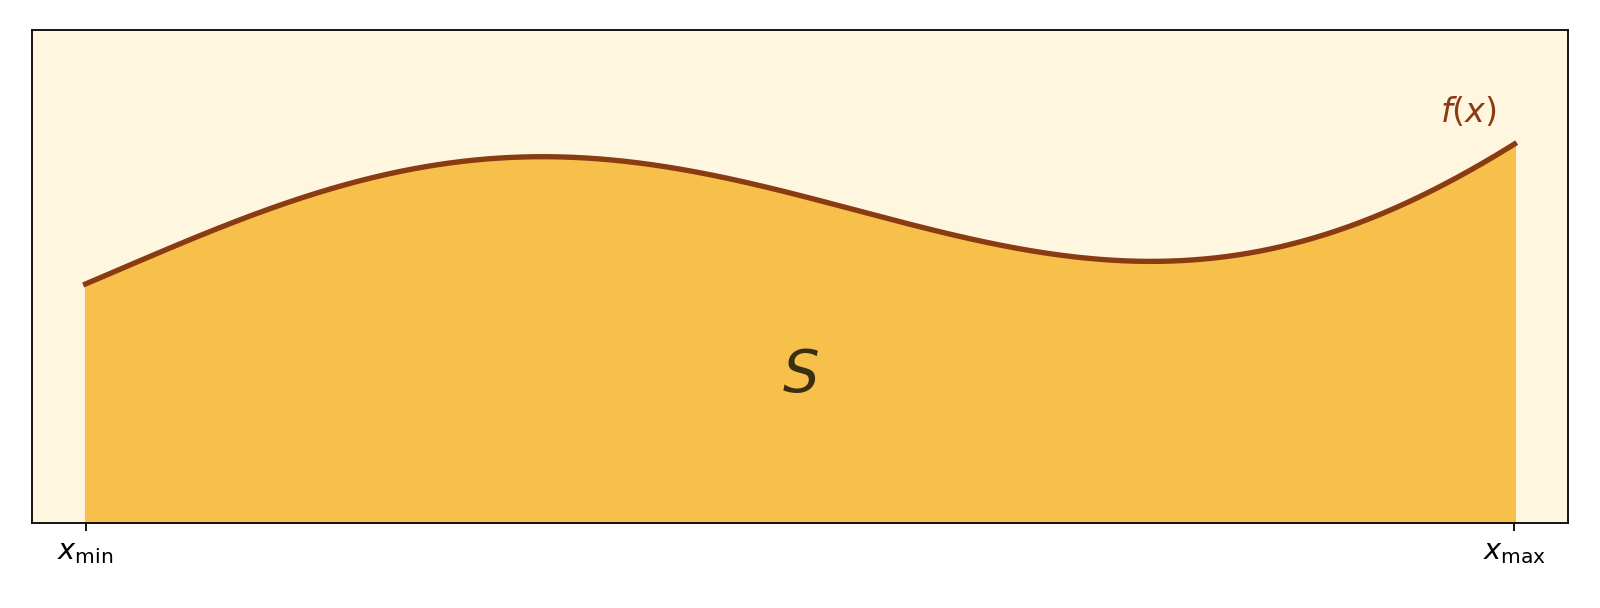

Разрежем отрезок на $N$ бинов одинаковой ширины:
$$x_i = x_{\min} + i\,\Delta x, \qquad \Delta x = \frac{x_{\max} - x_{\min}}{N}, \qquad i = 0, \dots, N.$$

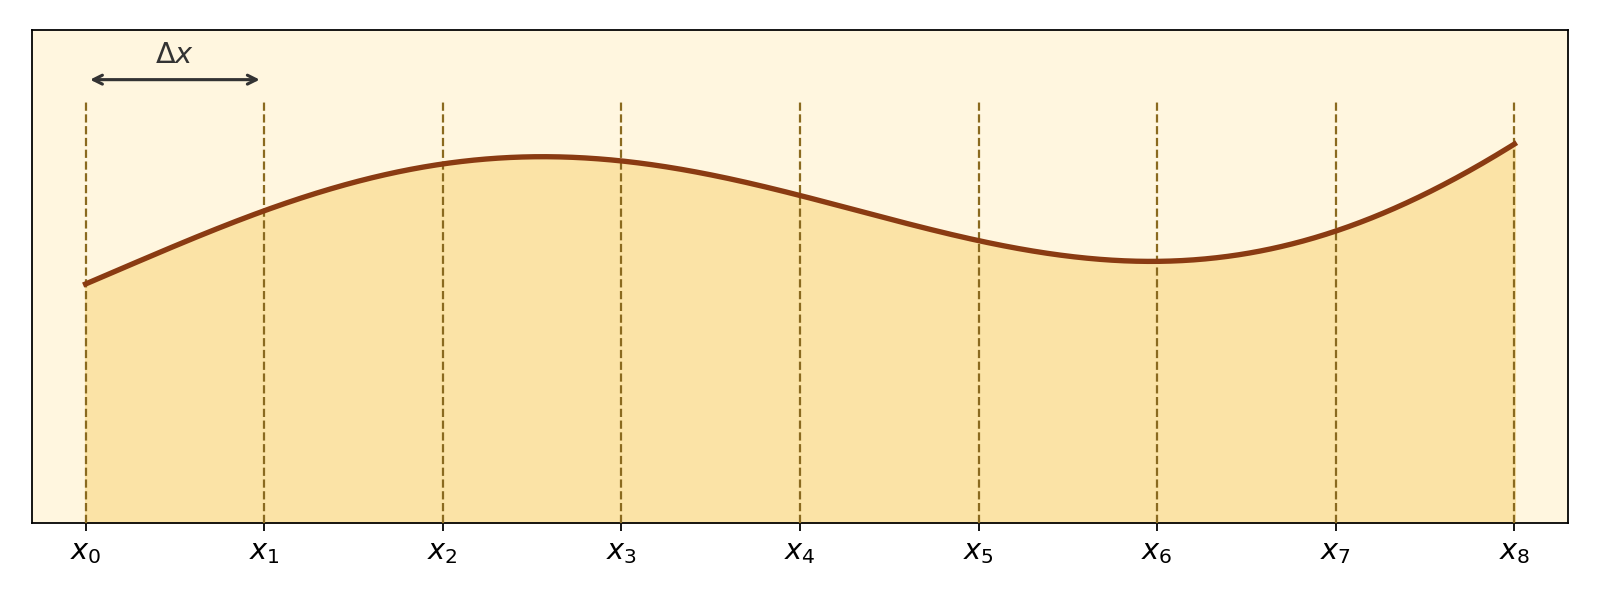

На каждом бине $[x_{i-1},\ x_i]$ заменим кривую прямоугольником высотой $f(\xi_i)$, где $\xi_i$ — середина бина. Площадь одного прямоугольника — $f(\xi_i)\,\Delta x$, площадь всех — интегральная сумма:
$$S_N = \sum_{i=1}^{N} f(\xi_i)\,\Delta x.$$
Красным — ошибка между кривой и прямоугольниками. Если устремить $\Delta x \to 0$, каждый прямоугольник превращается в $f(x)\,dx$, ошибка исчезает, а сумма становится интегралом:
$$\lim_{\Delta x \to 0} S_N = \int_{x_{\min}}^{x_{\max}} f(x)\,dx = S.$$

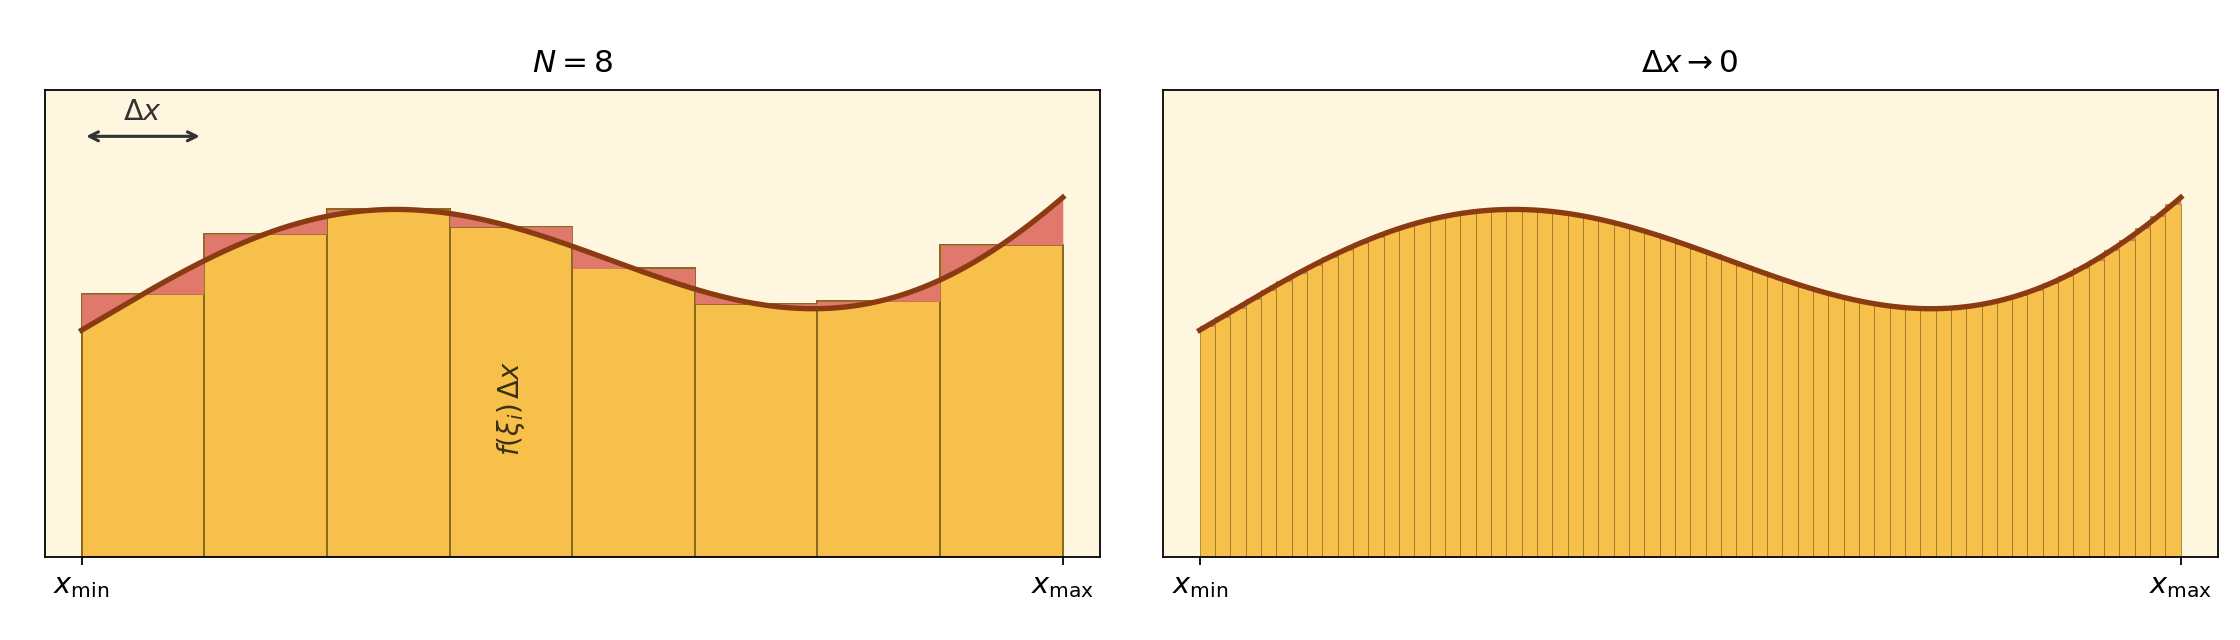

На компьютере этот предел недостижим: $\Delta x$ не может быть меньше расстояния между соседними числами, которые умеет хранить тип данных. В fp16 около единицы это $2^{-10} \approx 0.001$. Любой тип данных — конечная сетка: если на значение отведено $b$ бит, бинов не больше $N = 2^b$, и каждый лишний бит вдвое уменьшает $\Delta x$.

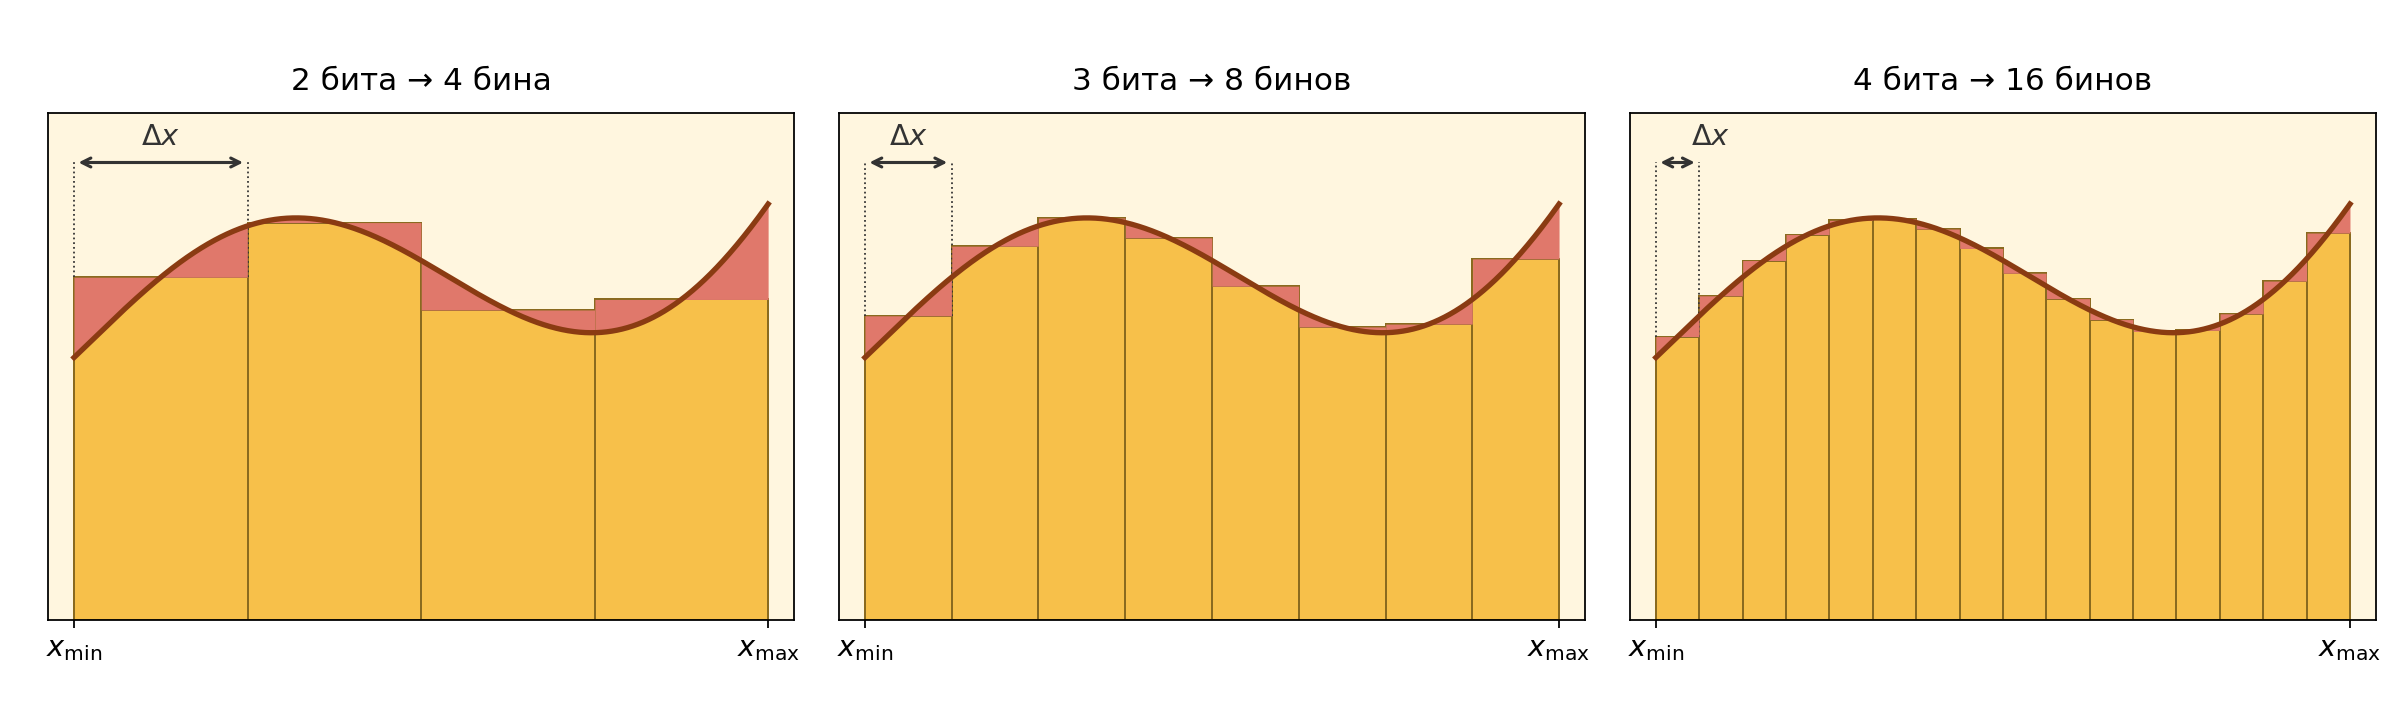

Но интеграл нам и не нужен. Нам нужно одно слагаемое — конкретная точка дискретного пространства: всё, что попало в бин $i$, заменяем одним значением $f(\xi_i)$. Это и есть квантизация: вместо $x$ храним номер бина ($b$ бит), а обратно получаем $f(\xi_i)$.

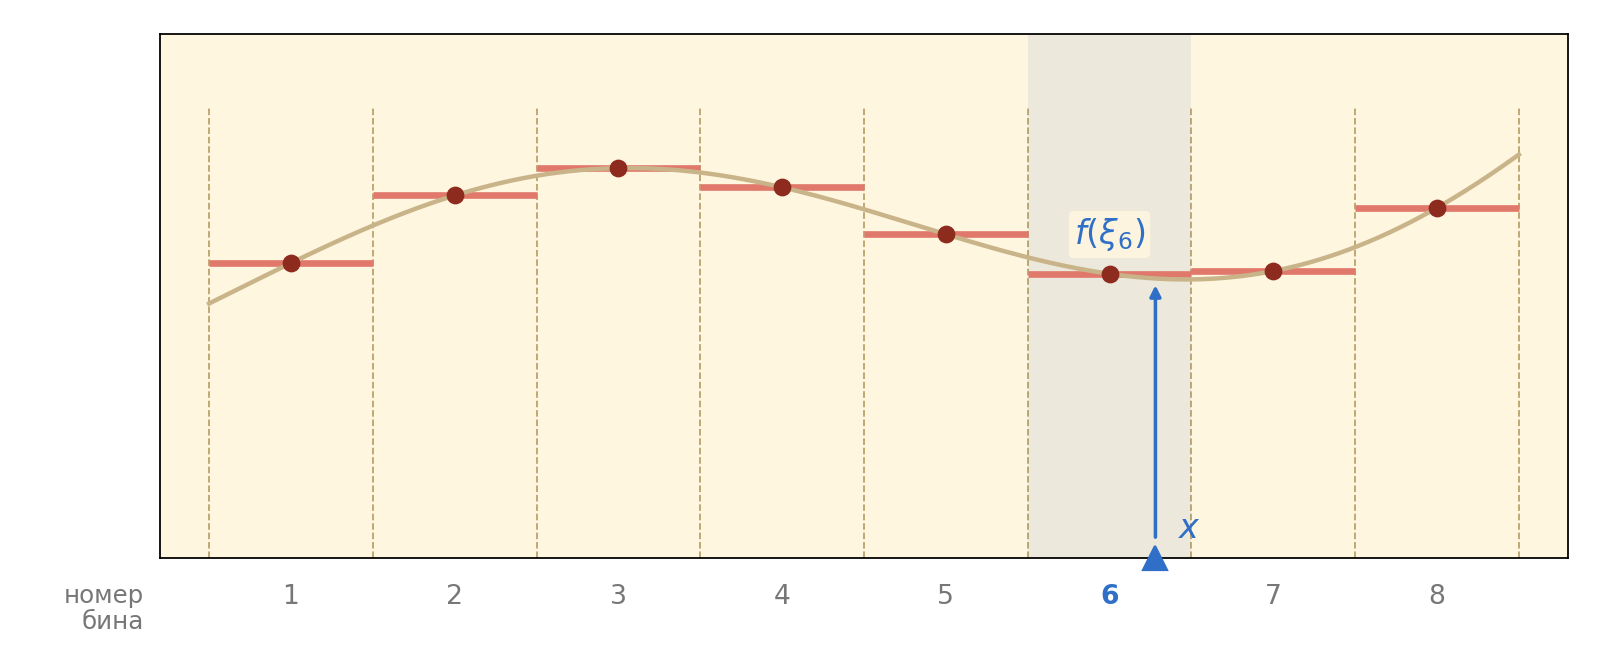

Посмотрим в варианте $Q(x), x$. каждое значение fp16 заменяем уровнем его бина, и получаются ступеньки. По x — значение fp16, по y — во что оно квантуется, а ширина ступеньки — это $\Delta x$. 

**У int все бины одинаковые, у fp они у нуля узкие и расширяются к краям.**

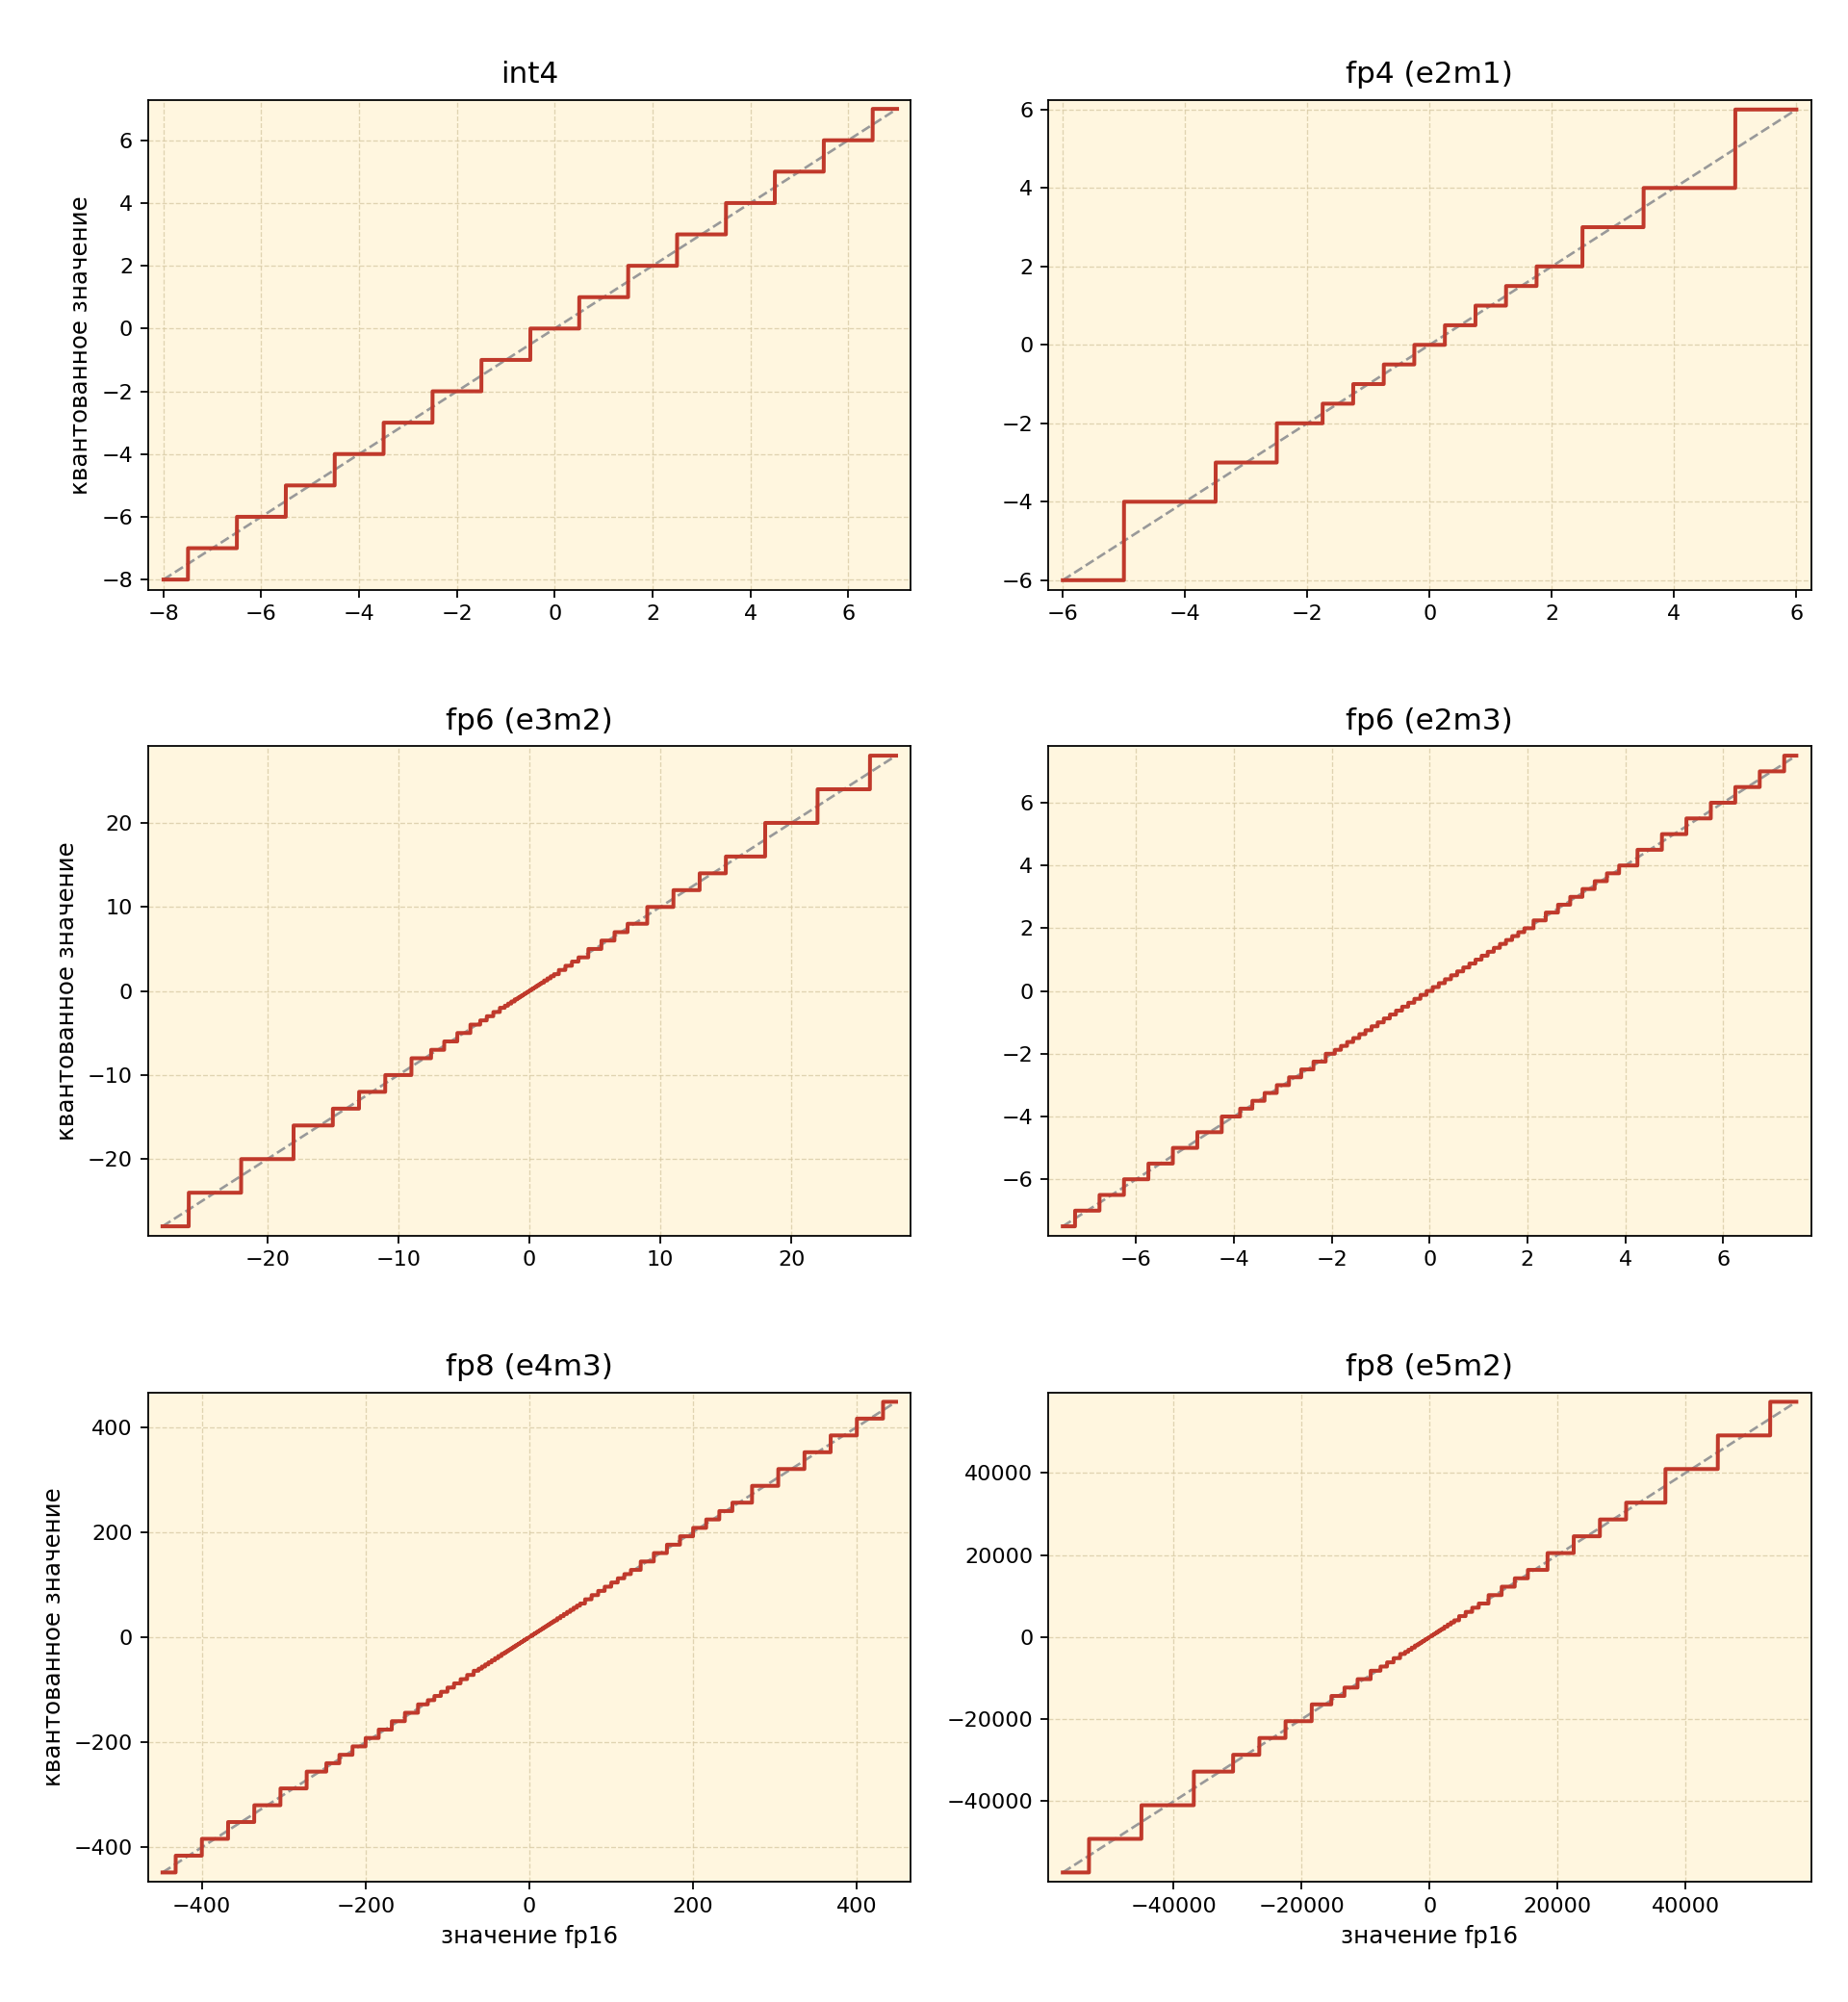

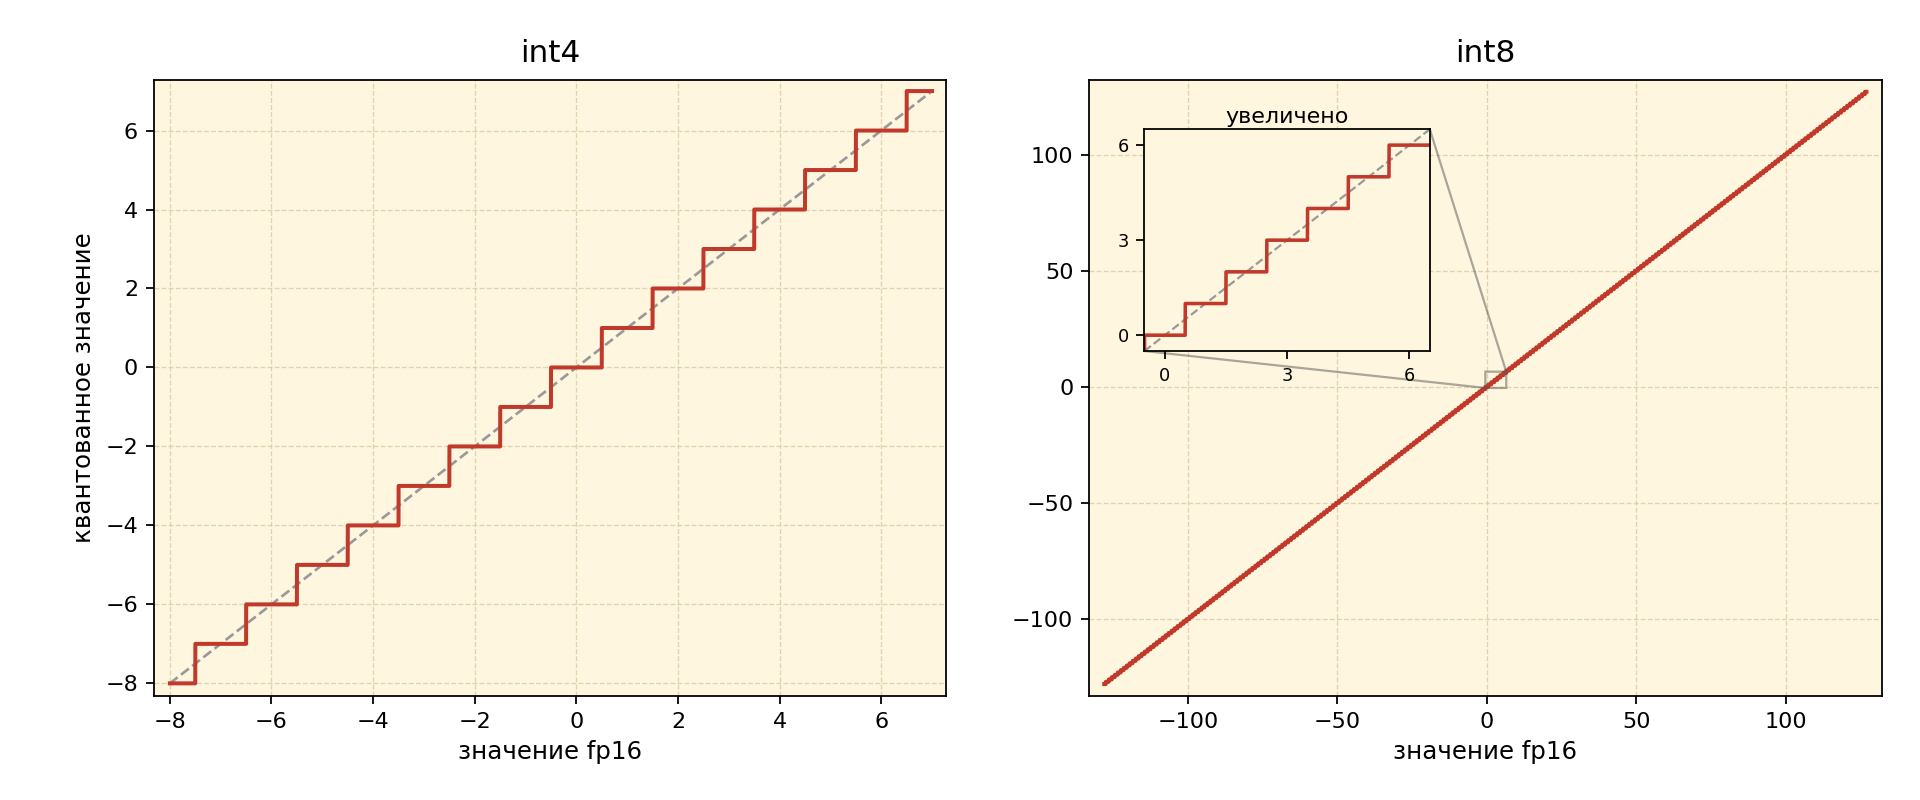

## Мотивация

Возьмём линейный слой размером с MLP у Llama-7B: `W` имеет форму 11008 × 4096 в fp16, это 86 МБ. Чтобы умножить на него один токен (`M = 1`, decode), всё равно нужно прочитать из памяти **все** веса. Посмотрим, как время зависит от `M`.

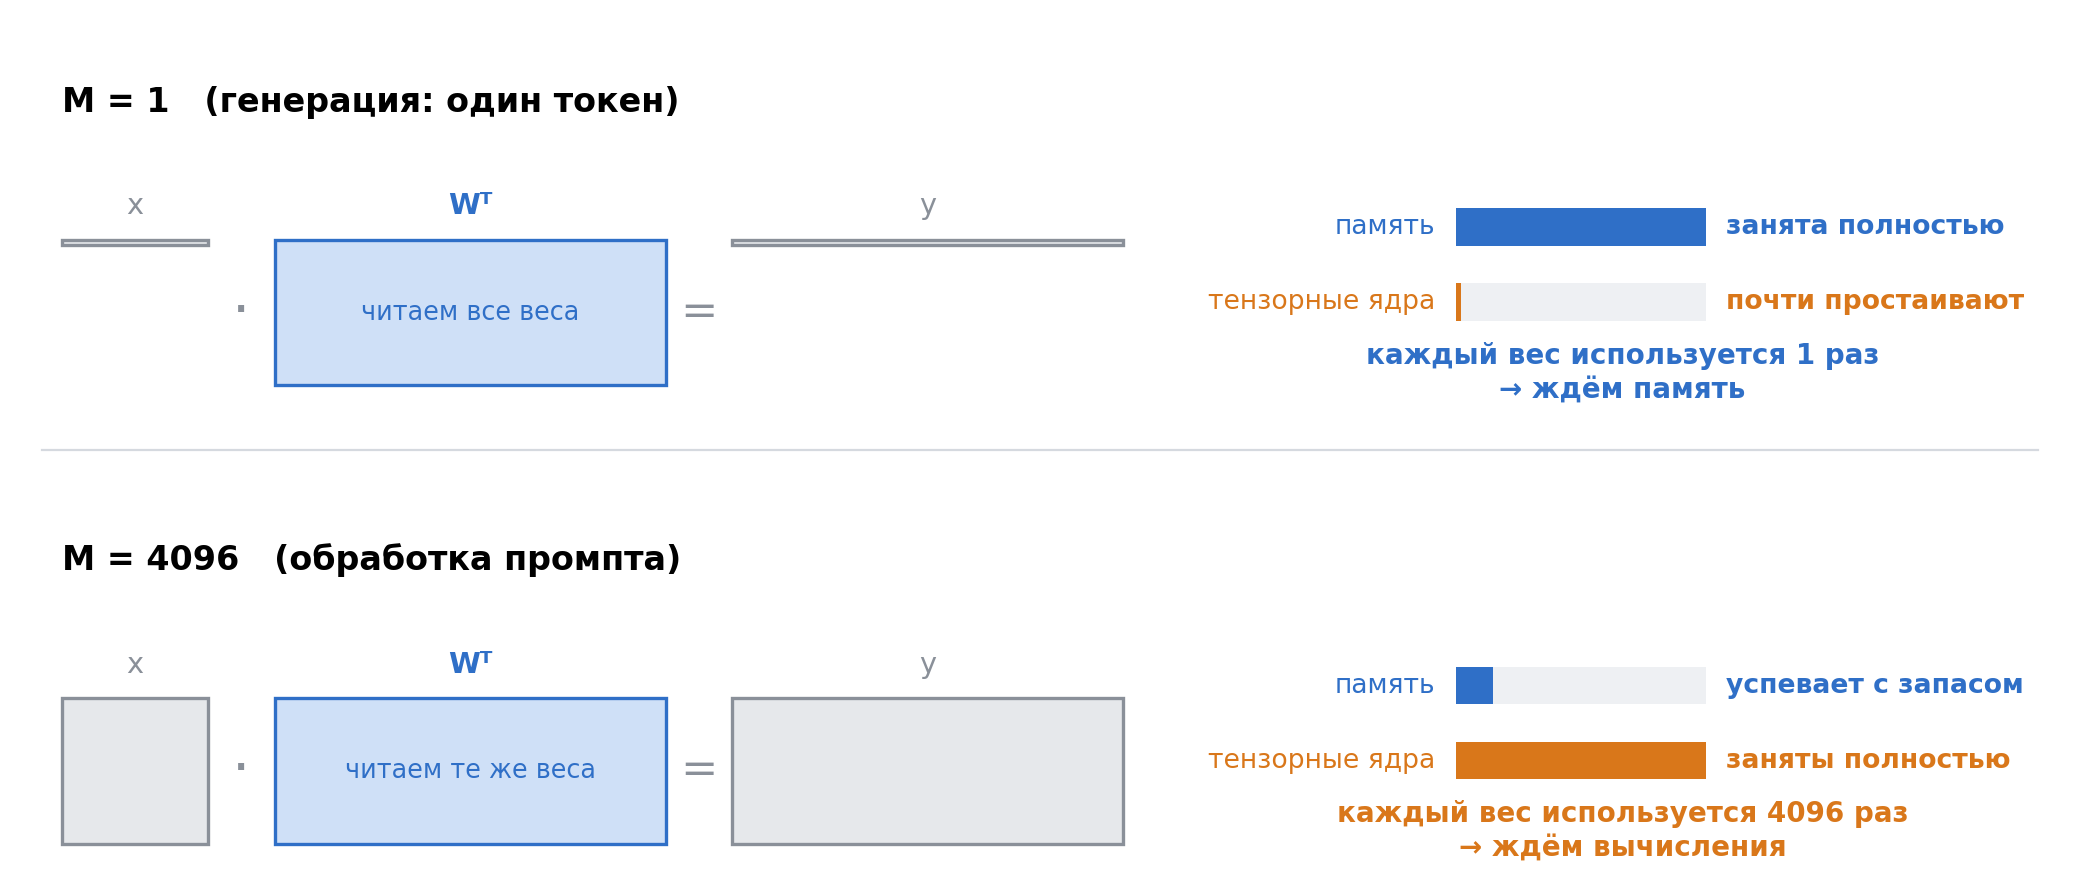

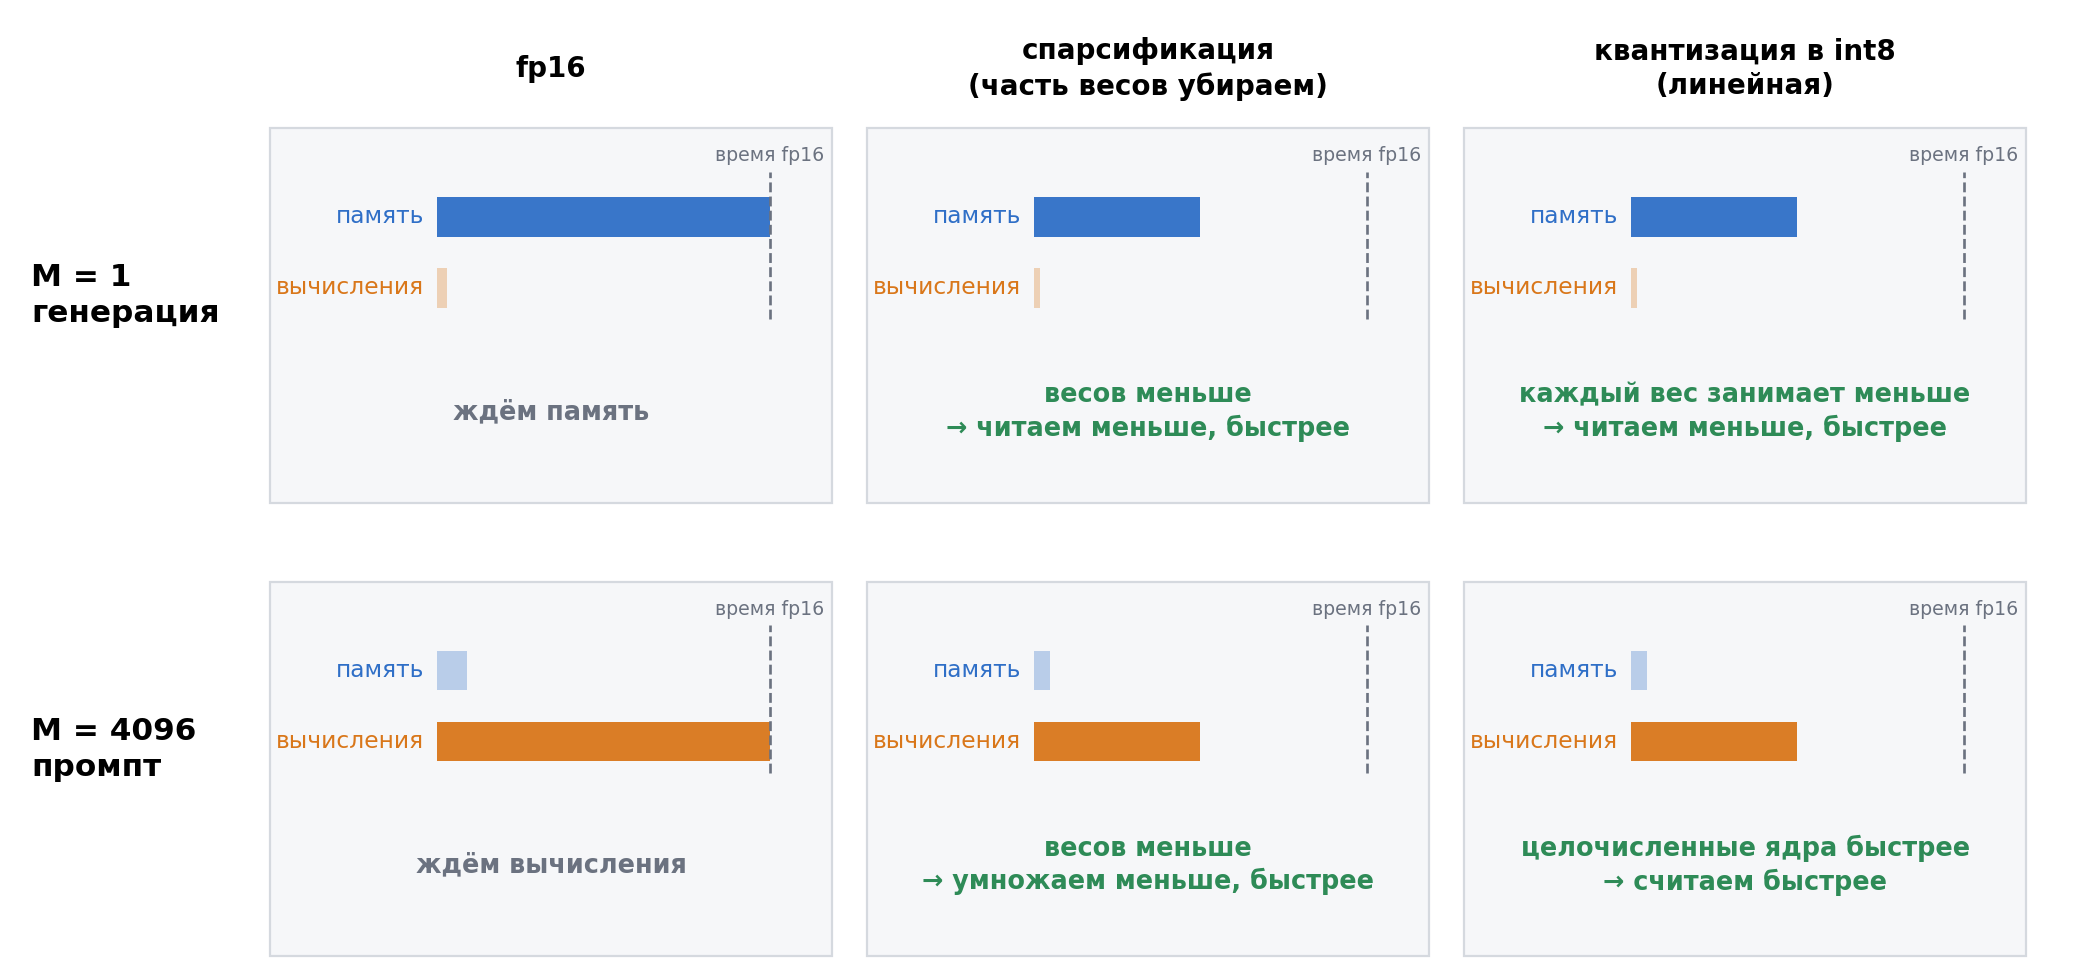

# 2. Часть I. Квантизация в INT8

## 2.1. Теория


**Линейная (равномерная) квантизация.** Уровни расположены с одинаковым шагом: значение умножаем на масштаб и округляем до целого. Здесь $b$ — число бит (для int8 $2^{b-1}-1 = 127$, $2^b-1 = 255$), $x_i$ — $i$-я строка матрицы.

**Симметричная** — диапазон $[-\max|x|,\ \max|x|]$, ноль переходит в ноль.

По всему тензору:
$$Q_{\text{tensor}}(X) = \mathrm{round}\left(\frac{2^{b-1}-1}{\mathrm{absmax}(X)} \cdot X\right)$$

По строкам:
$$Q_{\text{row}}\left(\begin{bmatrix} x_1 \\ \vdots \\ x_m \end{bmatrix}\right) = \mathrm{round}\left(\begin{bmatrix} \dfrac{2^{b-1}-1}{\mathrm{absmax}(x_1)} \cdot x_1 \\ \vdots \\ \dfrac{2^{b-1}-1}{\mathrm{absmax}(x_m)} \cdot x_m \end{bmatrix}\right)$$

**Несимметричная** — диапазон $[x_{\min},\ x_{\max}]$, сначала сдвигаем данные к нулю.

По всему тензору:
$$Q_{\text{tensor}}(X) = \mathrm{round}\left(\frac{2^{b}-1}{x_{\max} - x_{\min}} \cdot (X - x_{\min})\right)$$

По строкам:
$$Q_{\text{row}}\left(\begin{bmatrix} x_1 \\ \vdots \\ x_m \end{bmatrix}\right) = \mathrm{round}\left(\begin{bmatrix} \dfrac{2^{b}-1}{x_{\max,1} - x_{\min,1}} \cdot (x_1 - x_{\min,1}) \\ \vdots \\ \dfrac{2^{b}-1}{x_{\max,m} - x_{\min,m}} \cdot (x_m - x_{\min,m}) \end{bmatrix}\right)$$

Обратное преобразование — делим на тот же множитель, а в несимметричной ещё прибавляем $x_{\min}$.


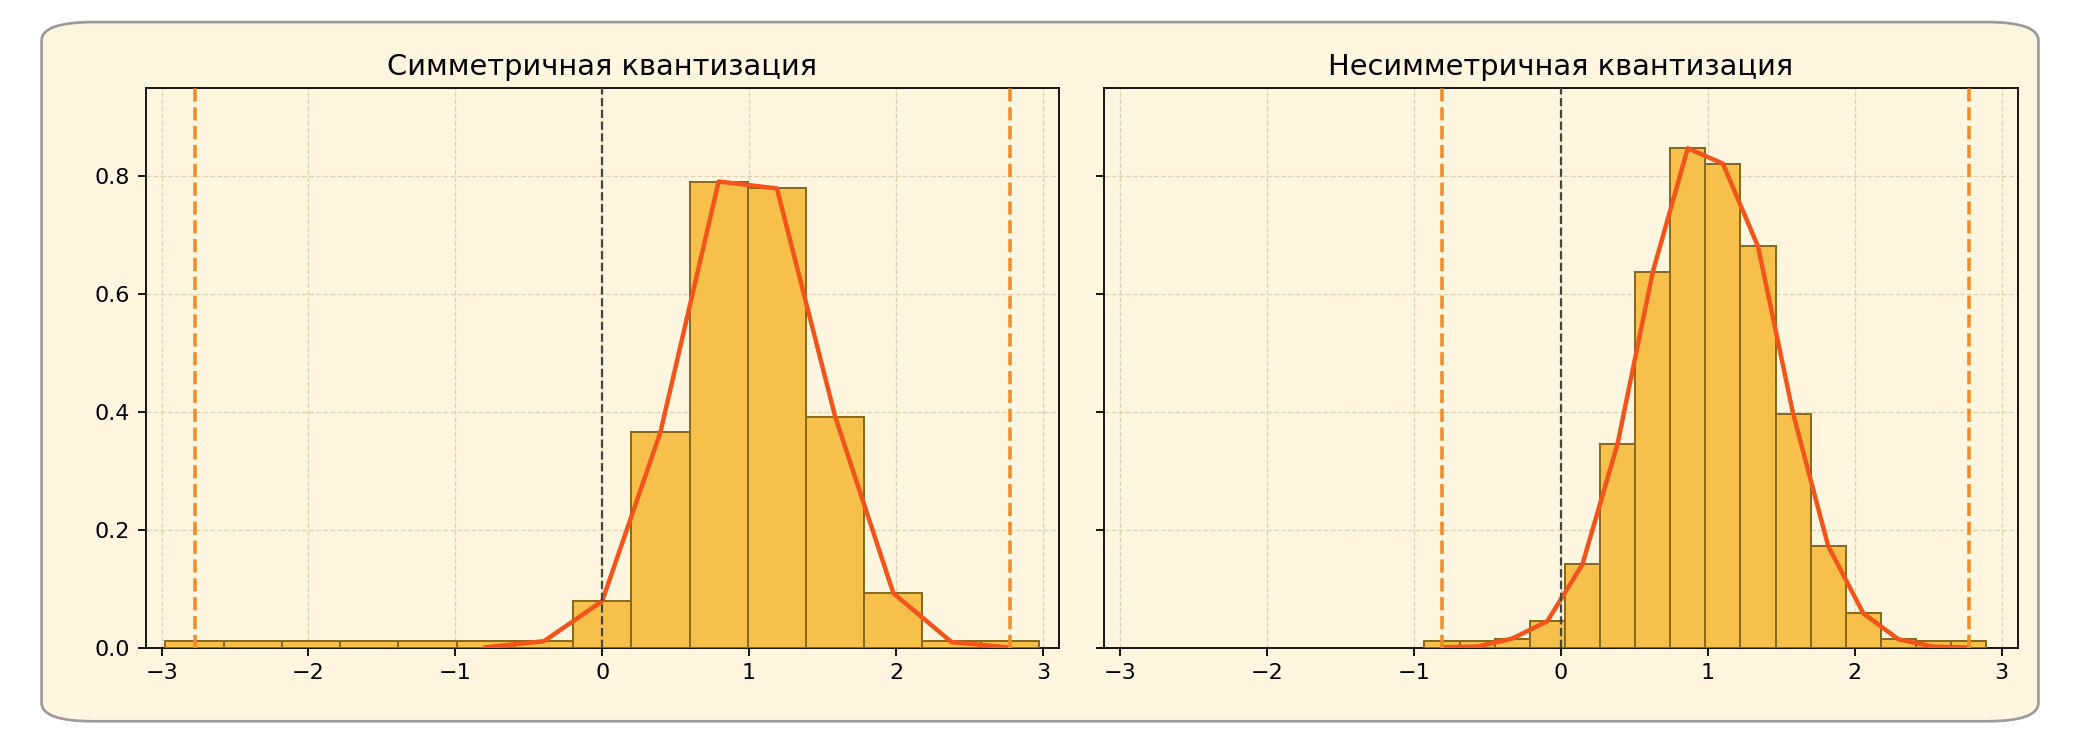

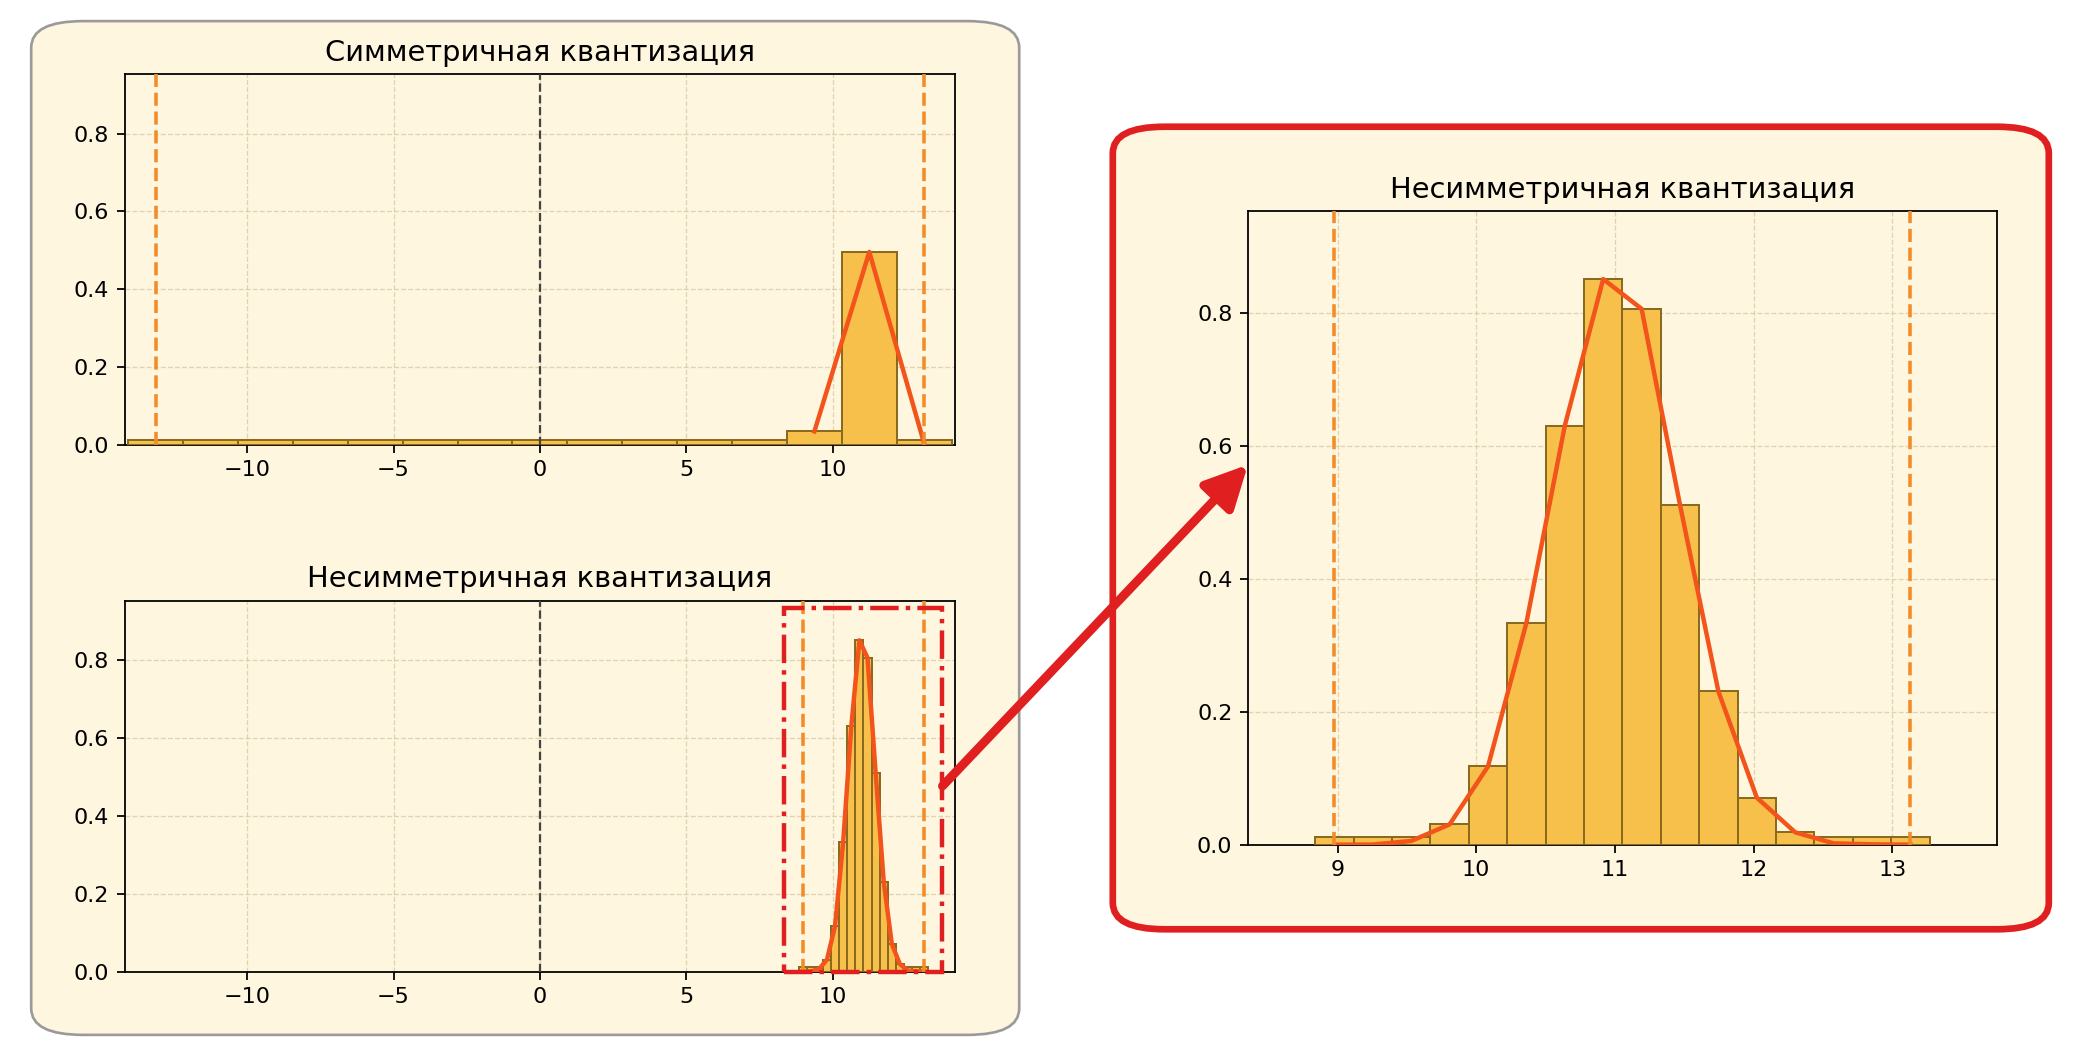

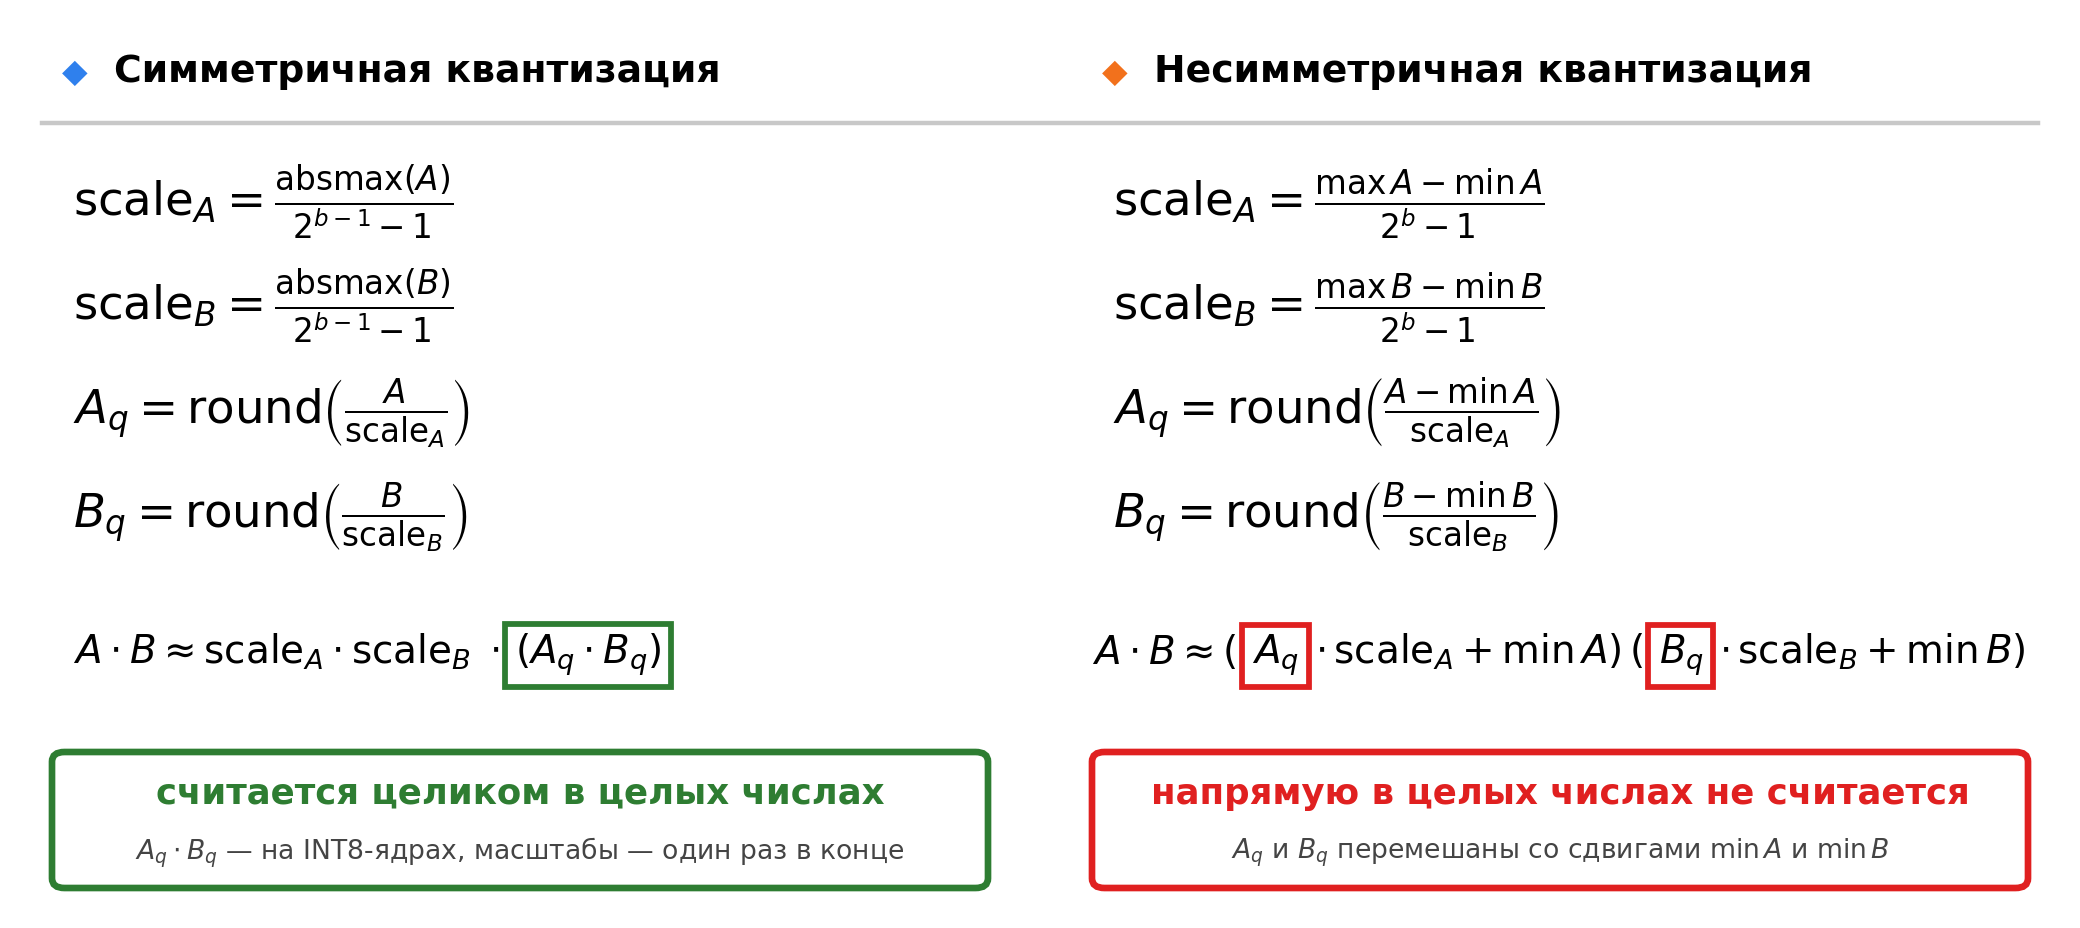

## 2.2. Линейная симметричная INT8 по строкам

In [16]:
def torch_quantize_rowwise(x):
    absmax = x.abs().amax(dim=1)
    q = torch.round(x / absmax[:, None] * 127.0).to(torch.int8)
    return q, absmax.half()


torch_quantize_rowwise_compiled = torch.compile(torch_quantize_rowwise)

### Triton 

In [17]:
@triton.jit
def quantize_rowwise_kernel(x_ptr, q_ptr, absmax_ptr, K, BLOCK_K: tl.constexpr):
    row = tl.program_id(0)                                      
    offs = tl.arange(0, BLOCK_K)
    mask = offs < K
    x = tl.load(x_ptr + row * K + offs, mask=mask, other=0.0).to(tl.float32)

    absmax = tl.max(tl.abs(x), axis=0)                           
    q = libdevice.rint(x / absmax * 127.0)                       

    tl.store(q_ptr + row * K + offs, q.to(tl.int8), mask=mask)  
    tl.store(absmax_ptr + row, absmax)


def triton_quantize_rowwise(x):
    assert x.is_contiguous()
    M, K = x.shape
    q = torch.empty((M, K), dtype=torch.int8, device=x.device)
    absmax = torch.empty(M, dtype=torch.float16, device=x.device)
    quantize_rowwise_kernel[(M,)](x, q, absmax, K, BLOCK_K=triton.next_power_of_2(K))
    return q, absmax

| PyTorch | Triton |
|---|---|
| `absmax = x.abs().amax(dim=1)` | `absmax = tl.max(tl.abs(x), axis=0)` |
| `torch.round(x / absmax[:, None] * 127)` | `libdevice.rint(x / absmax * 127.0)` |
| `.to(torch.int8)` | `q.to(tl.int8)` |


### Прод-ядро bitsandbytes

In [18]:
from IPython.display import Code

Code(filename="bnbtriton/src/bnbtriton/quantize_rowwise.py", language="python")

import math

import torch

from bnbtriton.triton_utils import is_triton_available

if not is_triton_available():

    def quantize_rowwise(x: torch.Tensor):
        return None
else:
    import triton
    import triton.language as tl

    # rowwise quantize

    # TODO: autotune this better.
    @triton.autotune(
        configs=[
            triton.Config({}, num_stages=1, num_warps=8),
            triton.Config({}, num_stages=2, num_warps=8),
            triton.Config({}, num_stages=4, num_warps=8),
            triton.Config({}, num_stages=8, num_warps=8),
            triton.Config({}, num_stages=1),
            triton.Config({}, num_stages=2),
            triton.Config({}, num_stages=4),
            triton.Config({}, num_stages=8),
            triton.Config({}, num_warps=1),
            triton.Config({}, num_warps=2),
            triton.Config({}, num_warps=4),
            triton.Config({}, num_warps=8),
        ],
        key=["n_elements"],
    )
    @triton.jit
    def _quantize_rowwise(
        x_ptr,
        output_ptr,
        output_maxs,
        n_elements,
        BLOCK_SIZE: tl.constexpr,
        P2: tl.constexpr,
    ):
        pid = tl.program_id(axis=0)
        block_start = pid * BLOCK_SIZE
        arange = tl.arange(0, P2)
        offsets = block_start + arange
        row_mask = arange < BLOCK_SIZE
        x = tl.load(x_ptr + offsets, mask=row_mask)

        abs_x = tl.abs(x)
        max_val = tl.max(tl.where(row_mask, abs_x, 0), axis=0)
        output = tl.extra.cuda.libdevice.llrint(127.0 * (x / max_val))
        tl.store(output_ptr + offsets, output, mask=row_mask)
        tl.store(output_maxs + pid, max_val)

    def quantize_rowwise(x: torch.Tensor):
        output = torch.empty(*x.shape, device=x.device, dtype=torch.int8)
        output_maxs = torch.empty(x.shape[0], device=x.device, dtype=torch.float16)

        P2 = int(2 ** (math.ceil(math.log2(x.shape[1]))))

        assert x.is_cuda and output.is_cuda
        n_elements = output.numel()
        grid = lambda meta: (x.shape[0],)
        _quantize_rowwise[grid](x, output, output_maxs, n_elements, BLOCK_SIZE=x.shape[1], P2=P2)
        return output, output_maxs


### Скорость квантизации весов (11008 × 4096) и активаций (2048 × 4096)

In [19]:
X = torch.randn(2048, K, device=DEVICE, dtype=torch.float16)

for name, data in {"weights": W, "activations": X}.items():
    print(f"\n{name} {tuple(data.shape)}")
    bench({
        "torch_eager": lambda: torch_quantize_rowwise(data),
        "torch_compile": lambda: torch_quantize_rowwise_compiled(data),
        "bnb_triton": lambda: bnb_quantize_rowwise(data),
        "our_triton": lambda: triton_quantize_rowwise(data),
    })


weights (11008, 4096)
| вариант       |   время, ms | ускорение vs «torch_eager»   |
|---------------|-------------|------------------------------|
| torch_eager   |       0.802 | ×1.00                        |
| torch_compile |       0.097 | ×8.24                        |
| bnb_triton    |       0.088 | ×9.07                        |
| our_triton    |       0.089 | ×9.02                        |

activations (2048, 4096)
| вариант       |   время, ms | ускорение vs «torch_eager»   |
|---------------|-------------|------------------------------|
| torch_eager   |       0.157 | ×1.00                        |
| torch_compile |       0.026 | ×5.93                        |
| bnb_triton    |       0.022 | ×7.07                        |
| our_triton    |       0.023 | ×6.78                        |


Деквантизация: `x̂ = q · absmax / 127`.

In [20]:
@triton.jit
def dequantize_rowwise_kernel(q_ptr, absmax_ptr, out_ptr, K, stride_q, stride_o, BLOCK_K: tl.constexpr):
    row = tl.program_id(0)
    offs = tl.arange(0, BLOCK_K)
    mask = offs < K
    q = tl.load(q_ptr + row * stride_q + offs, mask=mask, other=0).to(tl.float32)
    scale = tl.load(absmax_ptr + row).to(tl.float32) / 127.0
    tl.store(out_ptr + row * stride_o + offs, q * scale, mask=mask)


def triton_dequantize_rowwise(q, absmax):
    M, K = q.shape
    out = torch.empty((M, K), dtype=torch.float16, device=q.device)
    BLOCK_K = triton.next_power_of_2(K)
    dequantize_rowwise_kernel[(M,)](q, absmax, out, K, q.stride(0), out.stride(0),
                                    BLOCK_K=BLOCK_K, num_warps=8 if BLOCK_K >= 4096 else 4)
    return out


def torch_dequantize_rowwise(q, absmax):
    return (q.float() * (absmax.float() / 127)[:, None]).half()


q_our, s_our = triton_quantize_rowwise(W)
torch.testing.assert_close(triton_dequantize_rowwise(q_our, s_our), torch_dequantize_rowwise(q_our, s_our))
bench({
    "torch_eager": lambda: torch_dequantize_rowwise(q_our, s_our),
    "bnb_triton": lambda: bnb_dequantize_rowwise(q_our, s_our),
    "our_triton": lambda: triton_dequantize_rowwise(q_our, s_our),
})

| вариант     |   время, ms | ускорение vs «torch_eager»   |
|-------------|-------------|------------------------------|
| torch_eager |       0.615 | ×1.00                        |
| bnb_triton  |       0.092 | ×6.69                        |
| our_triton  |       0.092 | ×6.70                        |


## 2.3. Линейная несимметричная INT8 по строкам

Теперь диапазон каждой строки — $[x_{\min},\ x_{\max}]$, а не $[-\max|x|,\ \max|x|]$:
$$q = \mathrm{round}\left(\frac{255}{x_{\max} - x_{\min}} \cdot (x - x_{\min})\right) \in [0,\ 255], \qquad \hat x = q \cdot \frac{x_{\max} - x_{\min}}{255} + x_{\min}$$

Отличия от симметричной:
- коды неотрицательные, от 0 до 255, поэтому храним их в `uint8`;
- на каждую строку храним два числа: $x_{\min}$ и $x_{\max}$.

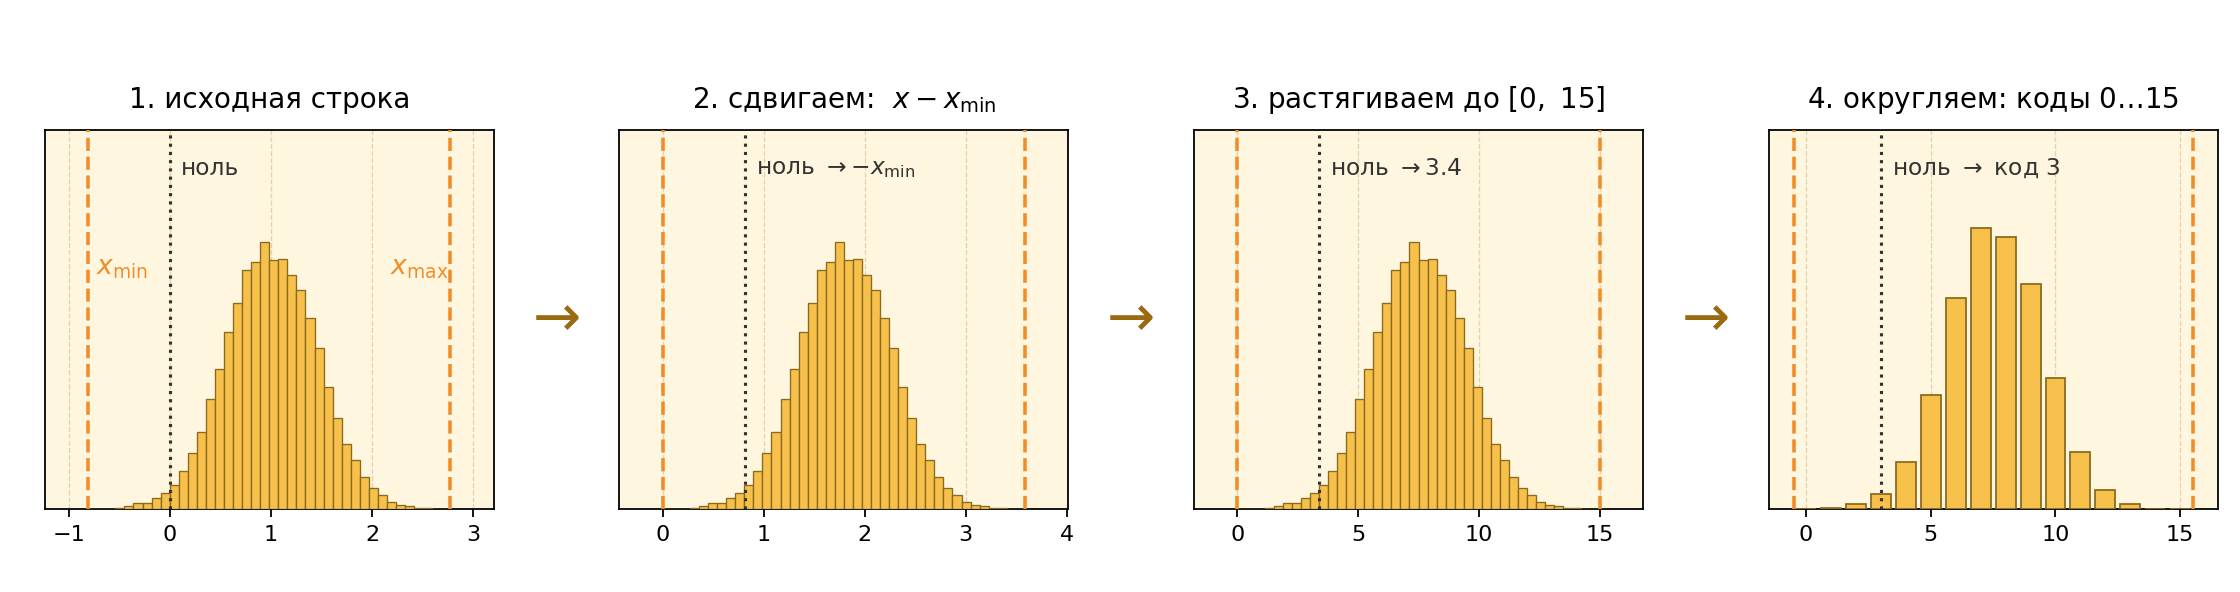

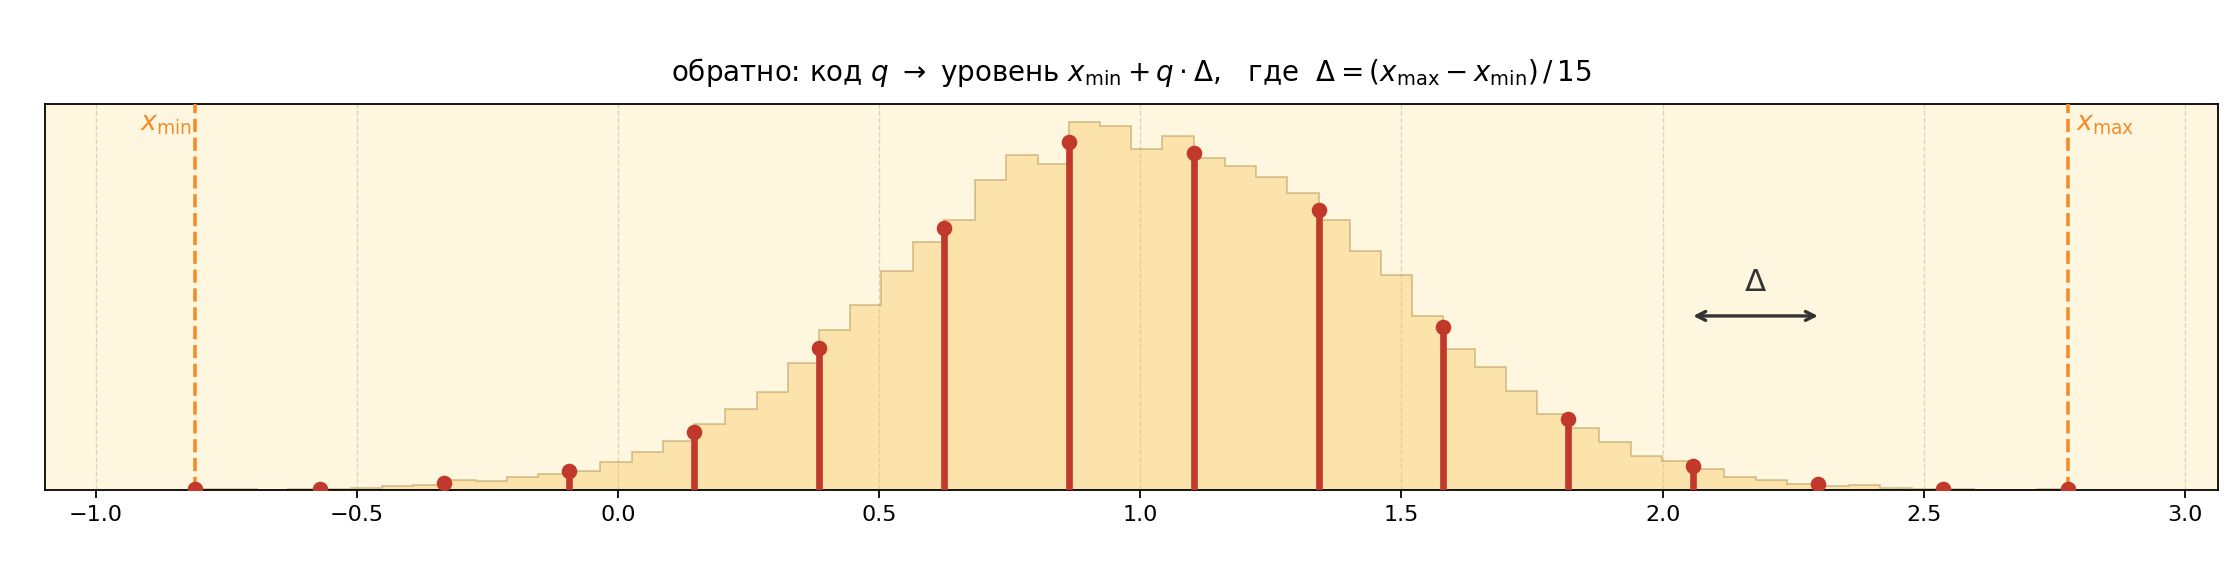

Для наглядности на картинках 4 бита, коды 0…15. В int8 всё так же, только кодов 256.

In [21]:
def torch_quantize_rowwise_asym(x):
    xmin = x.amin(dim=1)
    xmax = x.amax(dim=1)
    q = torch.round((x - xmin[:, None]) / (xmax - xmin)[:, None] * 255.0).to(torch.uint8)
    return q, xmin.half(), xmax.half()


def torch_dequantize_rowwise_asym(q, xmin, xmax):
    scale = (xmax.float() - xmin.float()) / 255.0
    return (q.float() * scale[:, None] + xmin.float()[:, None]).half()


torch_quantize_rowwise_asym_compiled = torch.compile(torch_quantize_rowwise_asym)

### Triton ядро

| PyTorch | Triton |
|---|---|
| `xmin = x.amin(dim=1)` | `xmin = tl.min(tl.where(mask, x, float("inf")), axis=0)` |
| `xmax = x.amax(dim=1)` | `xmax = tl.max(tl.where(mask, x, float("-inf")), axis=0)` |
| `torch.round((x - xmin) / (xmax - xmin) * 255)` | `libdevice.rint((x - xmin) / (xmax - xmin) * 255.0)` |
| `.to(torch.uint8)` | `q.to(tl.uint8)` |


In [22]:
@triton.jit
def quantize_rowwise_asym_kernel(x_ptr, q_ptr, xmin_ptr, xmax_ptr, K, BLOCK_K: tl.constexpr):
    row = tl.program_id(0)                                      
    offs = tl.arange(0, BLOCK_K)
    mask = offs < K
    x = tl.load(x_ptr + row * K + offs, mask=mask, other=0.0).to(tl.float32)

    xmin = tl.min(tl.where(mask, x, float("inf")), axis=0)     
    xmax = tl.max(tl.where(mask, x, float("-inf")), axis=0)     
    q = libdevice.rint((x - xmin) / (xmax - xmin) * 255.0)     

    tl.store(q_ptr + row * K + offs, q.to(tl.uint8), mask=mask)  
    tl.store(xmin_ptr + row, xmin)
    tl.store(xmax_ptr + row, xmax)


def triton_quantize_rowwise_asym(x):
    assert x.is_contiguous()
    M, K = x.shape
    q = torch.empty((M, K), dtype=torch.uint8, device=x.device)
    xmin = torch.empty(M, dtype=torch.float16, device=x.device)
    xmax = torch.empty(M, dtype=torch.float16, device=x.device)
    quantize_rowwise_asym_kernel[(M,)](x, q, xmin, xmax, K, BLOCK_K=triton.next_power_of_2(K))
    return q, xmin, xmax

In [23]:
q_t, mn_t, mx_t = torch_quantize_rowwise_asym(W)
q_o, mn_o, mx_o = triton_quantize_rowwise_asym(W)

diff = (q_o.int() - q_t.int()).abs()
print(f"наше vs torch: max |Δq| = {diff.max().item()}, совпадает {(diff == 0).float().mean().item():.4%}, "
      f"min и max равны: {torch.equal(mn_o, mn_t) and torch.equal(mx_o, mx_t)}")

for name, data in {"weights": W, "activations": X}.items():
    print(f"\n{name} {tuple(data.shape)}")
    bench({
        "torch_eager": lambda: torch_quantize_rowwise_asym(data),
        "torch_compile": lambda: torch_quantize_rowwise_asym_compiled(data),
        "our_triton": lambda: triton_quantize_rowwise_asym(data),
    })

наше vs torch: max |Δq| = 1, совпадает 94.5278%, min и max равны: True

weights (11008, 4096)
| вариант       |   время, ms | ускорение vs «torch_eager»   |
|---------------|-------------|------------------------------|
| torch_eager   |       0.948 | ×1.00                        |
| torch_compile |       0.122 | ×7.77                        |
| our_triton    |       0.09  | ×10.55                       |

activations (2048, 4096)
| вариант       |   время, ms | ускорение vs «torch_eager»   |
|---------------|-------------|------------------------------|
| torch_eager   |       0.193 | ×1.00                        |
| torch_compile |       0.031 | ×6.23                        |
| our_triton    |       0.023 | ×8.42                        |


**Когда несимметричная точнее**

In [24]:
cases = {
    "centered": torch.randn(1024, K, device=DEVICE),
    "shifted_small": 1.0 + 0.45 * torch.randn(1024, K, device=DEVICE),
    "shifted_large": 11.0 + 0.45 * torch.randn(1024, K, device=DEVICE),
}

rows = []
for name, data in cases.items():
    data = data.half()
    q, s = triton_quantize_rowwise(data)
    err_sym = rel_err(data, triton_dequantize_rowwise(q, s))
    q, mn, mx = triton_quantize_rowwise_asym(data)
    err_asym = rel_err(data, torch_dequantize_rowwise_asym(q, mn, mx))
    rows.append([name, f"{err_sym:.2e}", f"{err_asym:.2e}", f"×{err_sym / err_asym:.1f}"])

print(tabulate(rows, headers=["данные", "симметричная", "несимметричная", "во сколько раз точнее"], tablefmt="github"))

| данные        |   симметричная |   несимметричная | во сколько раз точнее   |
|---------------|----------------|------------------|-------------------------|
| centered      |        0.00863 |         0.0082   | ×1.1                    |
| shifted_small |        0.00546 |         0.00338  | ×1.6                    |
| shifted_large |        0.00261 |         0.000441 | ×5.9                    |


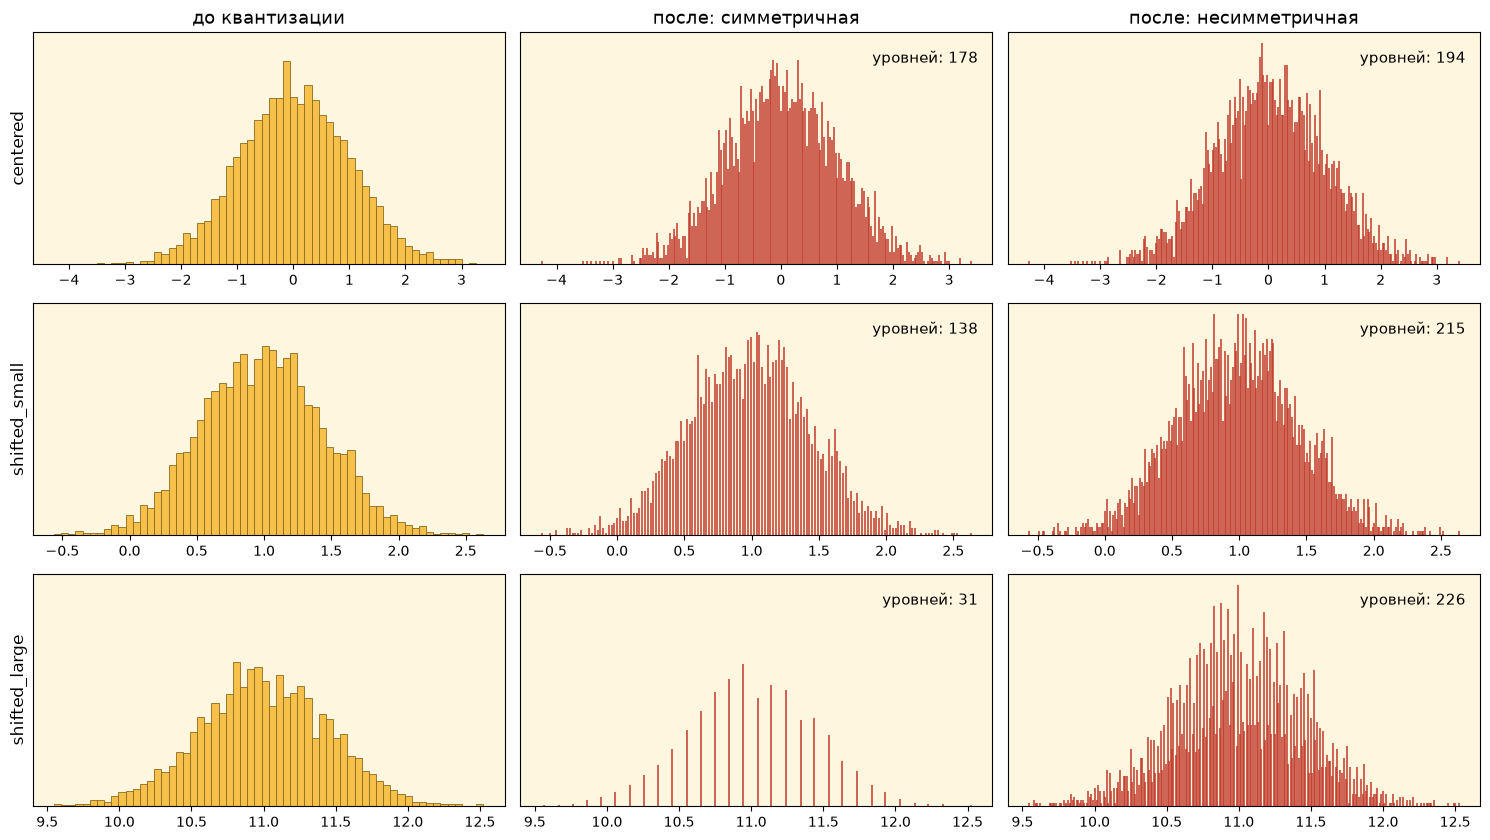

In [14]:
fig, axes = plt.subplots(len(cases), 3, figsize=(15, 8.5), sharex="row", sharey="row")
for row_axes, (name, data) in zip(axes, cases.items()):
    row = data[:1].half()                                    
    q, s = triton_quantize_rowwise(row)
    sym = triton_dequantize_rowwise(q, s), s.item() / 127
    q, mn, mx = triton_quantize_rowwise_asym(row)
    asym = torch_dequantize_rowwise_asym(q, mn, mx), (mx.item() - mn.item()) / 255

    row = row.float().flatten().cpu().numpy()
    row_axes[0].hist(row, bins=60, density=True, color="#F7C04A", ec="#8A6A1F", lw=0.6)
    for ax, (row_hat, step) in zip(row_axes[1:], (sym, asym)):
        levels, counts = torch.unique(row_hat.float().flatten().cpu(), return_counts=True)
        ax.vlines(levels.numpy(), 0, counts.numpy() / (row.size * step), color="#C0392B", lw=1.1)
        ax.text(0.97, 0.92, f"уровней: {len(levels)}", transform=ax.transAxes, ha="right", va="top", fontsize=11)
    for ax in row_axes:
        ax.set_facecolor("#FFF6DF")
        ax.set_yticks([])
    pad = 0.05 * (row.max() - row.min())
    row_axes[0].set_xlim(row.min() - pad, row.max() + pad)
    row_axes[0].set_ylabel(name, fontsize=12)

for ax, title in zip(axes[0], ("до квантизации", "после: симметричная", "после: несимметричная")):
    ax.set_title(title, fontsize=13)
fig.tight_layout()
plt.show()

- На центрированных данных схемы почти одинаковы.
- Чем сильнее данные смещены, тем больше выигрыш несимметричной. 
- По скорости квантизации схемы одинаковы. Но, как видно на картинке из 2.1, коды несимметричной нельзя напрямую перемножить на INT8-ядрах.

## 2.4. Векторная квантизация

До сих пор каждый вес квантовался отдельно. В **векторной** квантизации квантуют сразу группу из $d$ весов: группу заменяют номером похожего вектора из заранее подобранной таблицы — **кодовой книги**. Разберём по шагам на $d = 2$.

**Шаг 1.** Находим в строке самый большой по модулю вес: $\mathrm{absmax} = \max_i |w_i|$, в примере это $|-2.50| = 2.5$. Делим на него каждый вес строки. Теперь вся строка лежит в $[-1,\ 1]$, а сам максимум стал ровно $-1$. У разных строк веса разного масштаба, а кодовая книга одна на всю матрицу. После деления все строки в одном масштабе, и одна книга подходит ко всем. Сам absmax — одно число на строку, его храним, чтобы в конце умножить обратно. 

Затем режем строку на пары соседних весов по порядку: $(w_0, w_1), (w_2, w_3), \dots$ — в коде это `reshape(-1, d)`. 

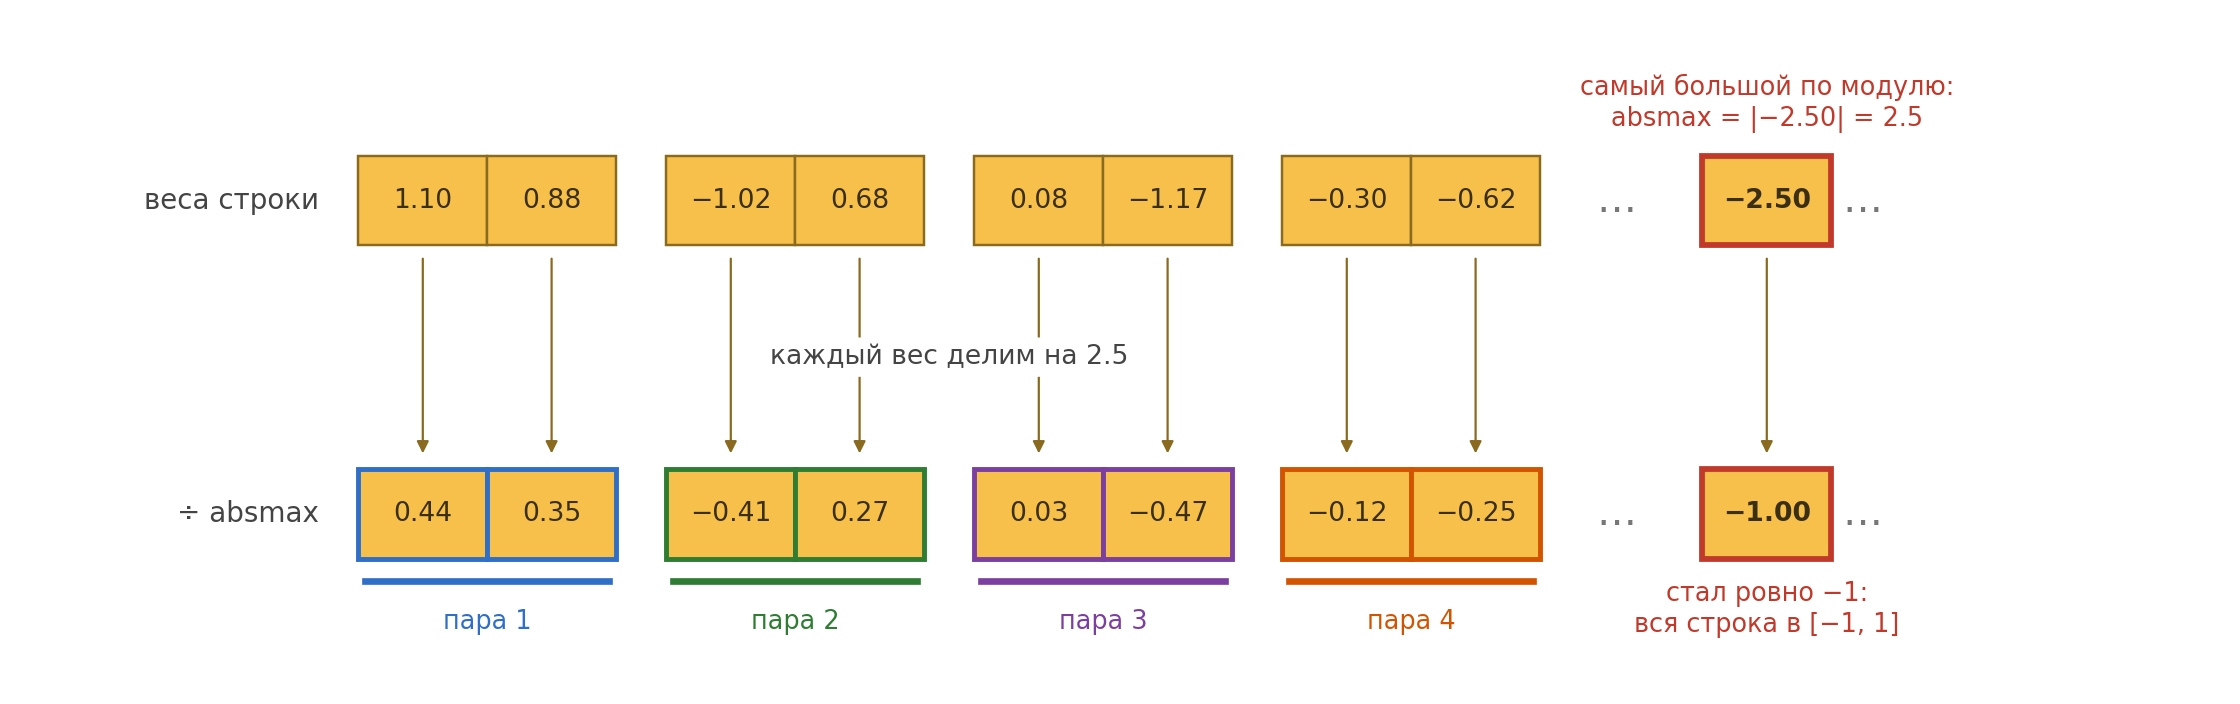

**Шаг 2.** Каждая пара — это точка на плоскости: первый вес — координата по x, второй — по y.

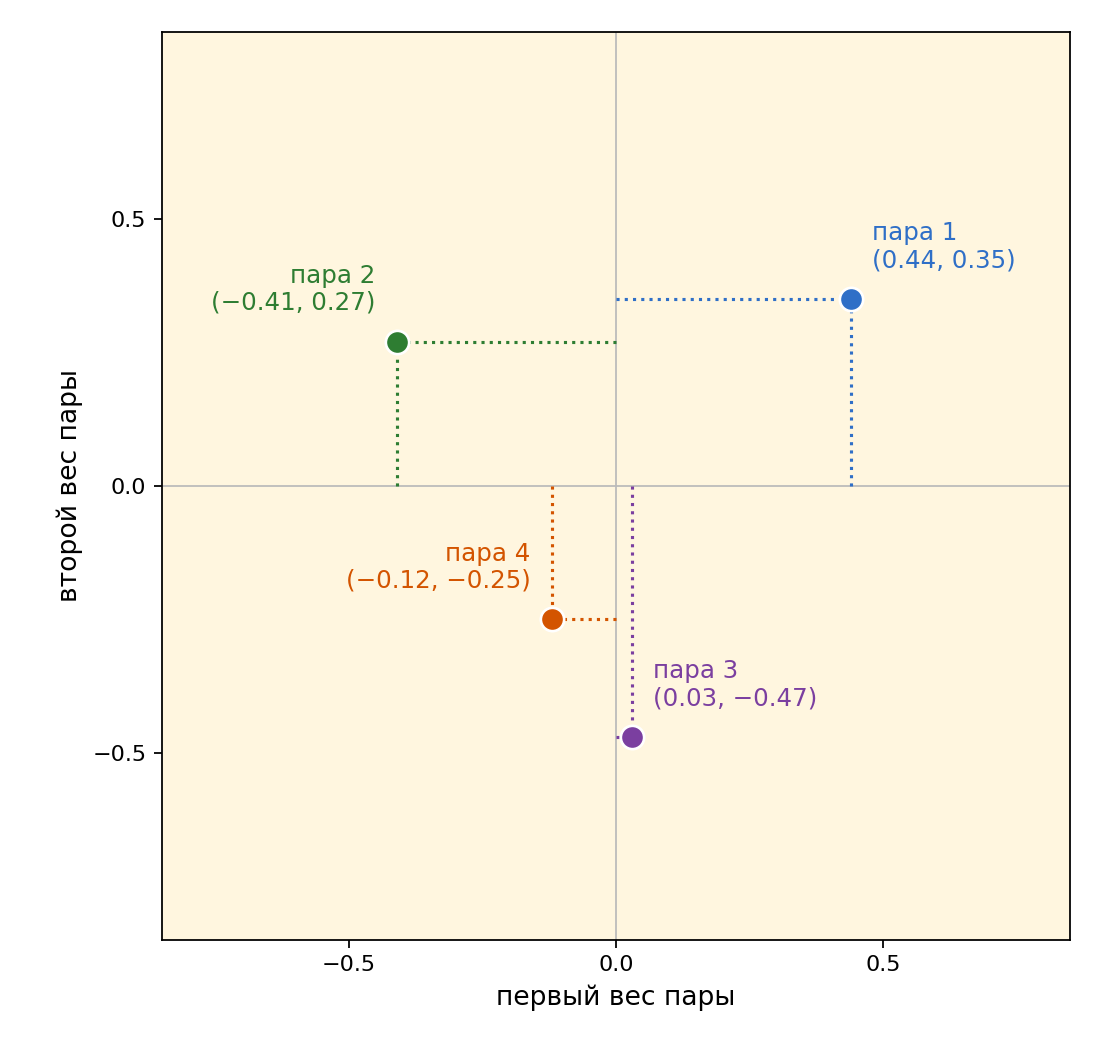

**Шаг 3.** Так раскладываем все пары матрицы. Веса распределены примерно нормально, поэтому точки собираются в облако вокруг нуля.

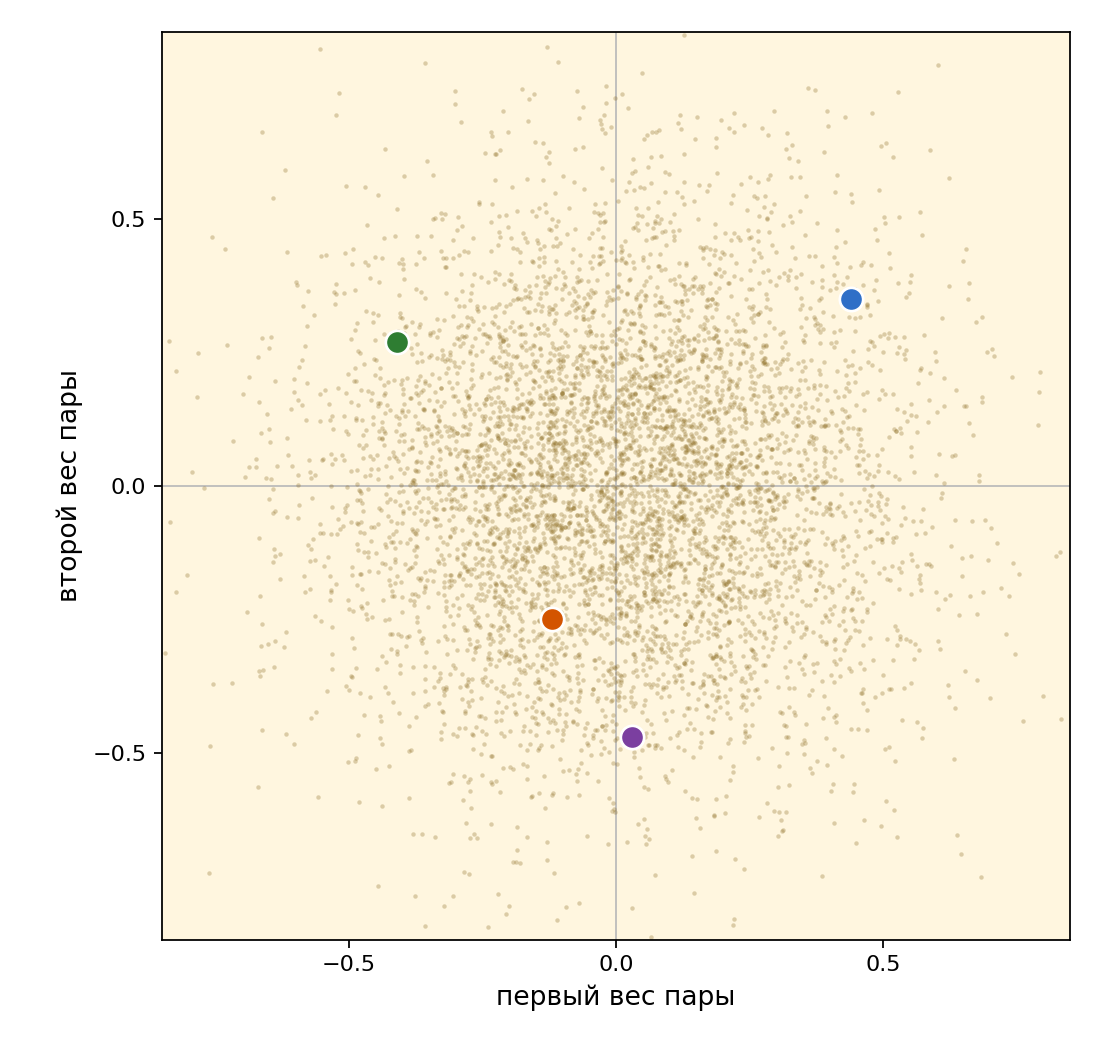

**Шаг 4.** Кодовую книгу подбираем k-means по этому облаку.

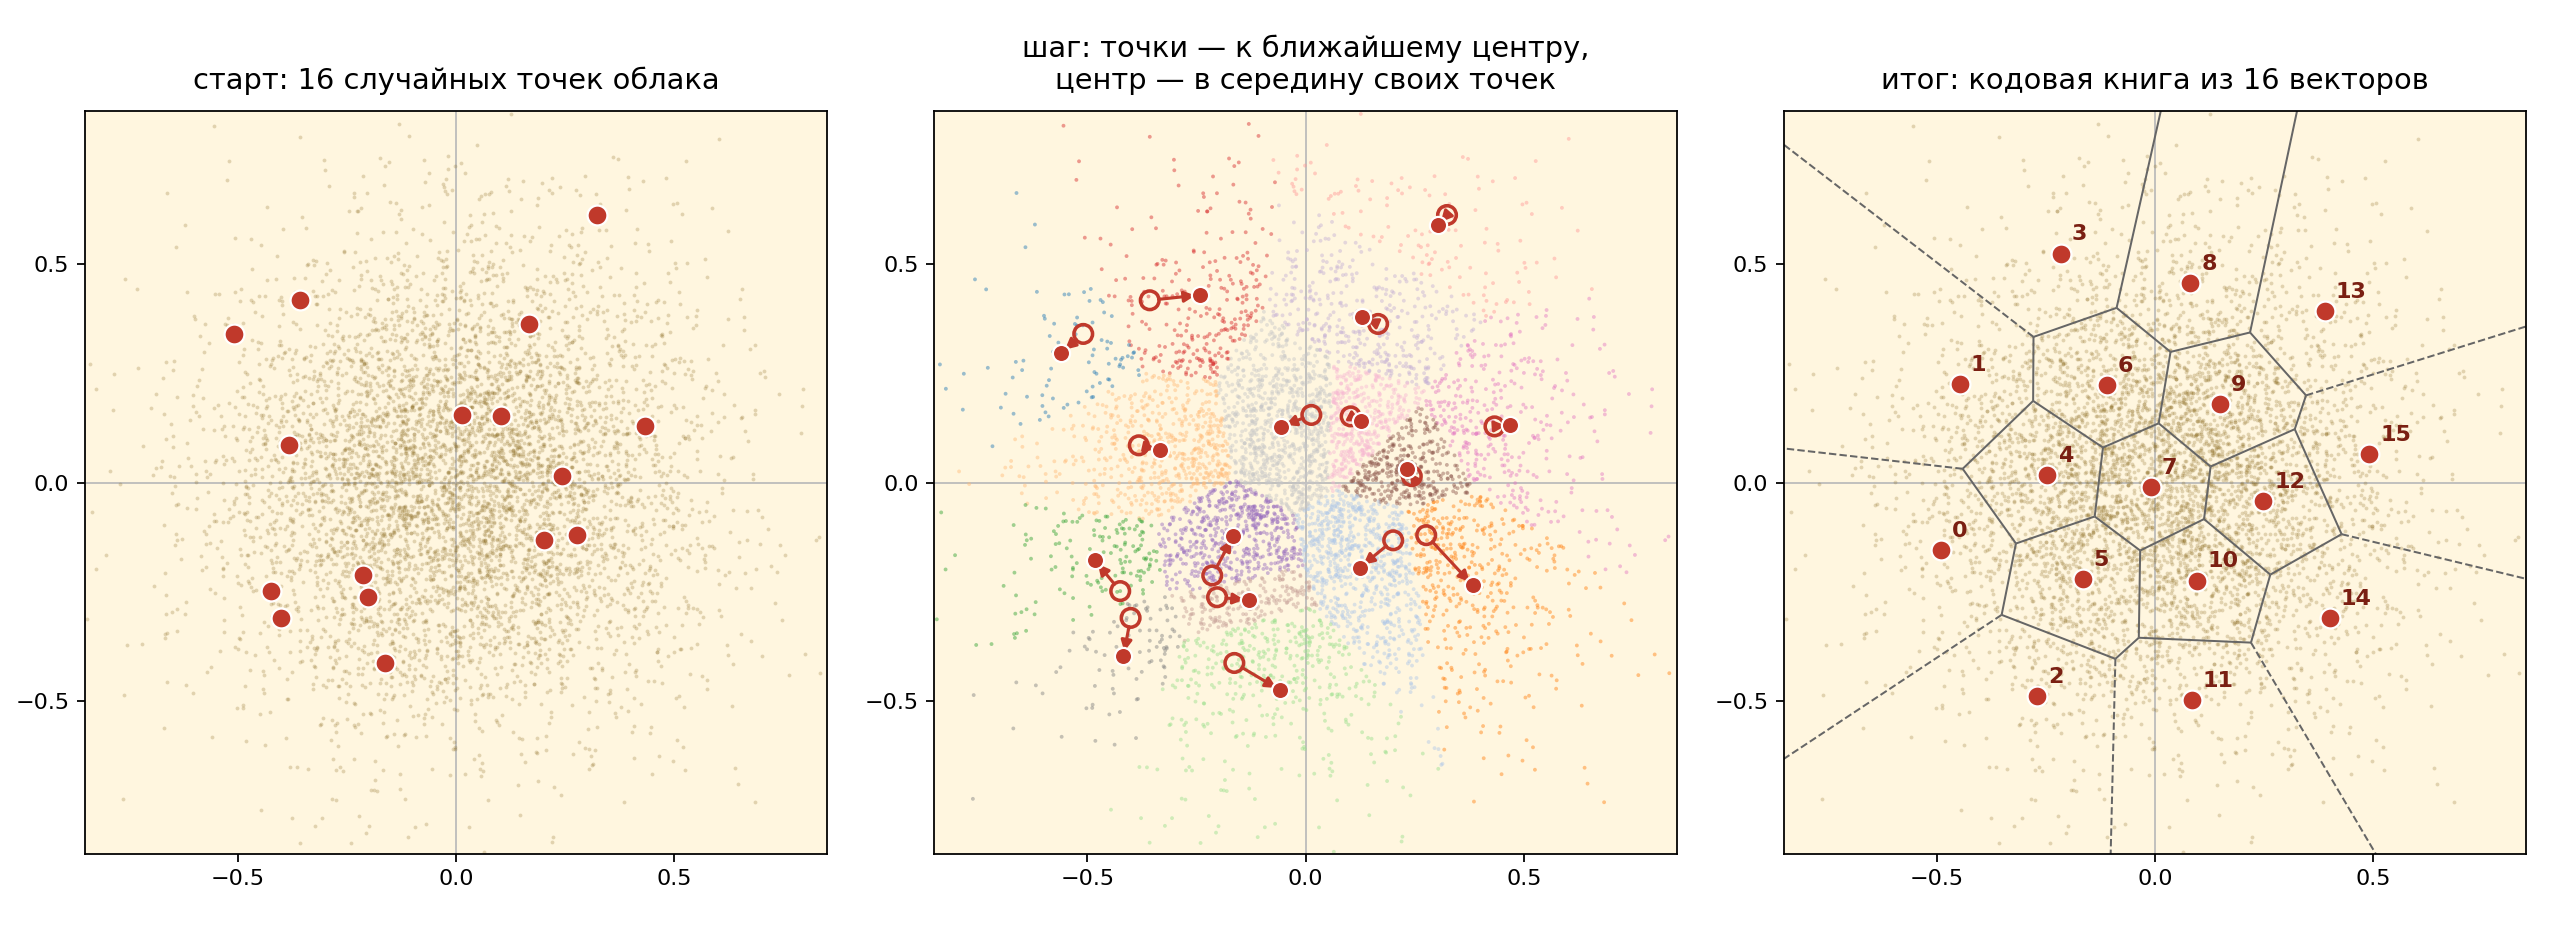

**Шаг 5.** Для каждой пары ищем ближайший вектор книги и запоминаем его номер. Все пары, попавшие в одну ячейку, получают один и тот же номер.

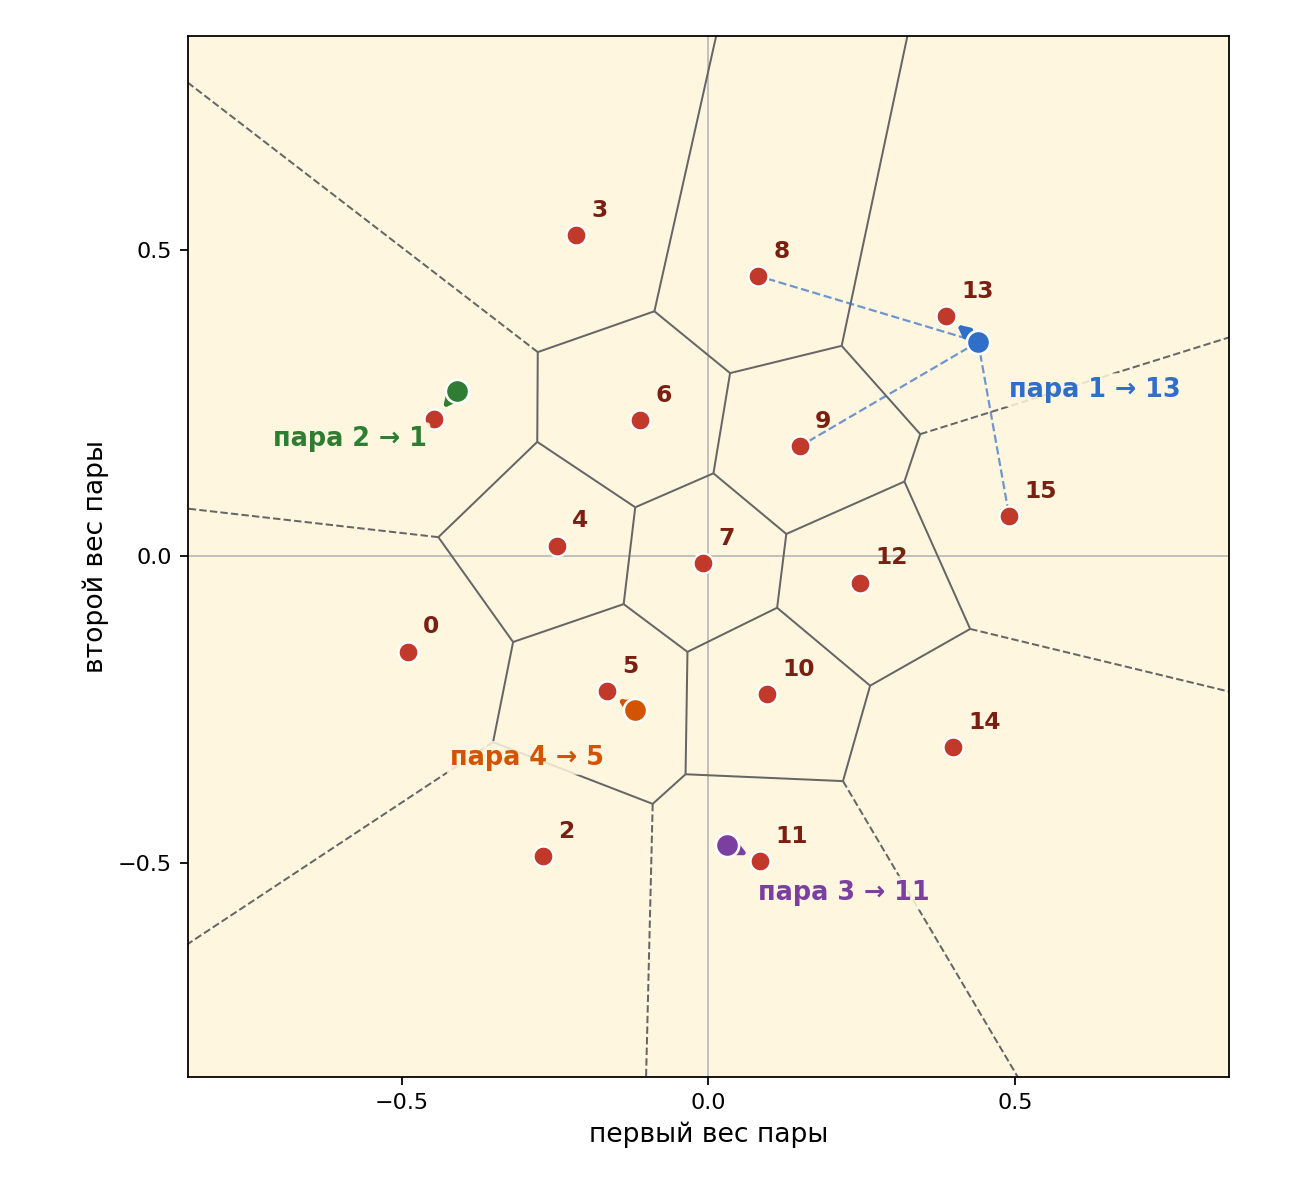

**Шаг 6.** Храним только номера — 1 байт на пару. Чтобы восстановить веса, берём вектор по номеру из книги и умножаем на absmax строки.

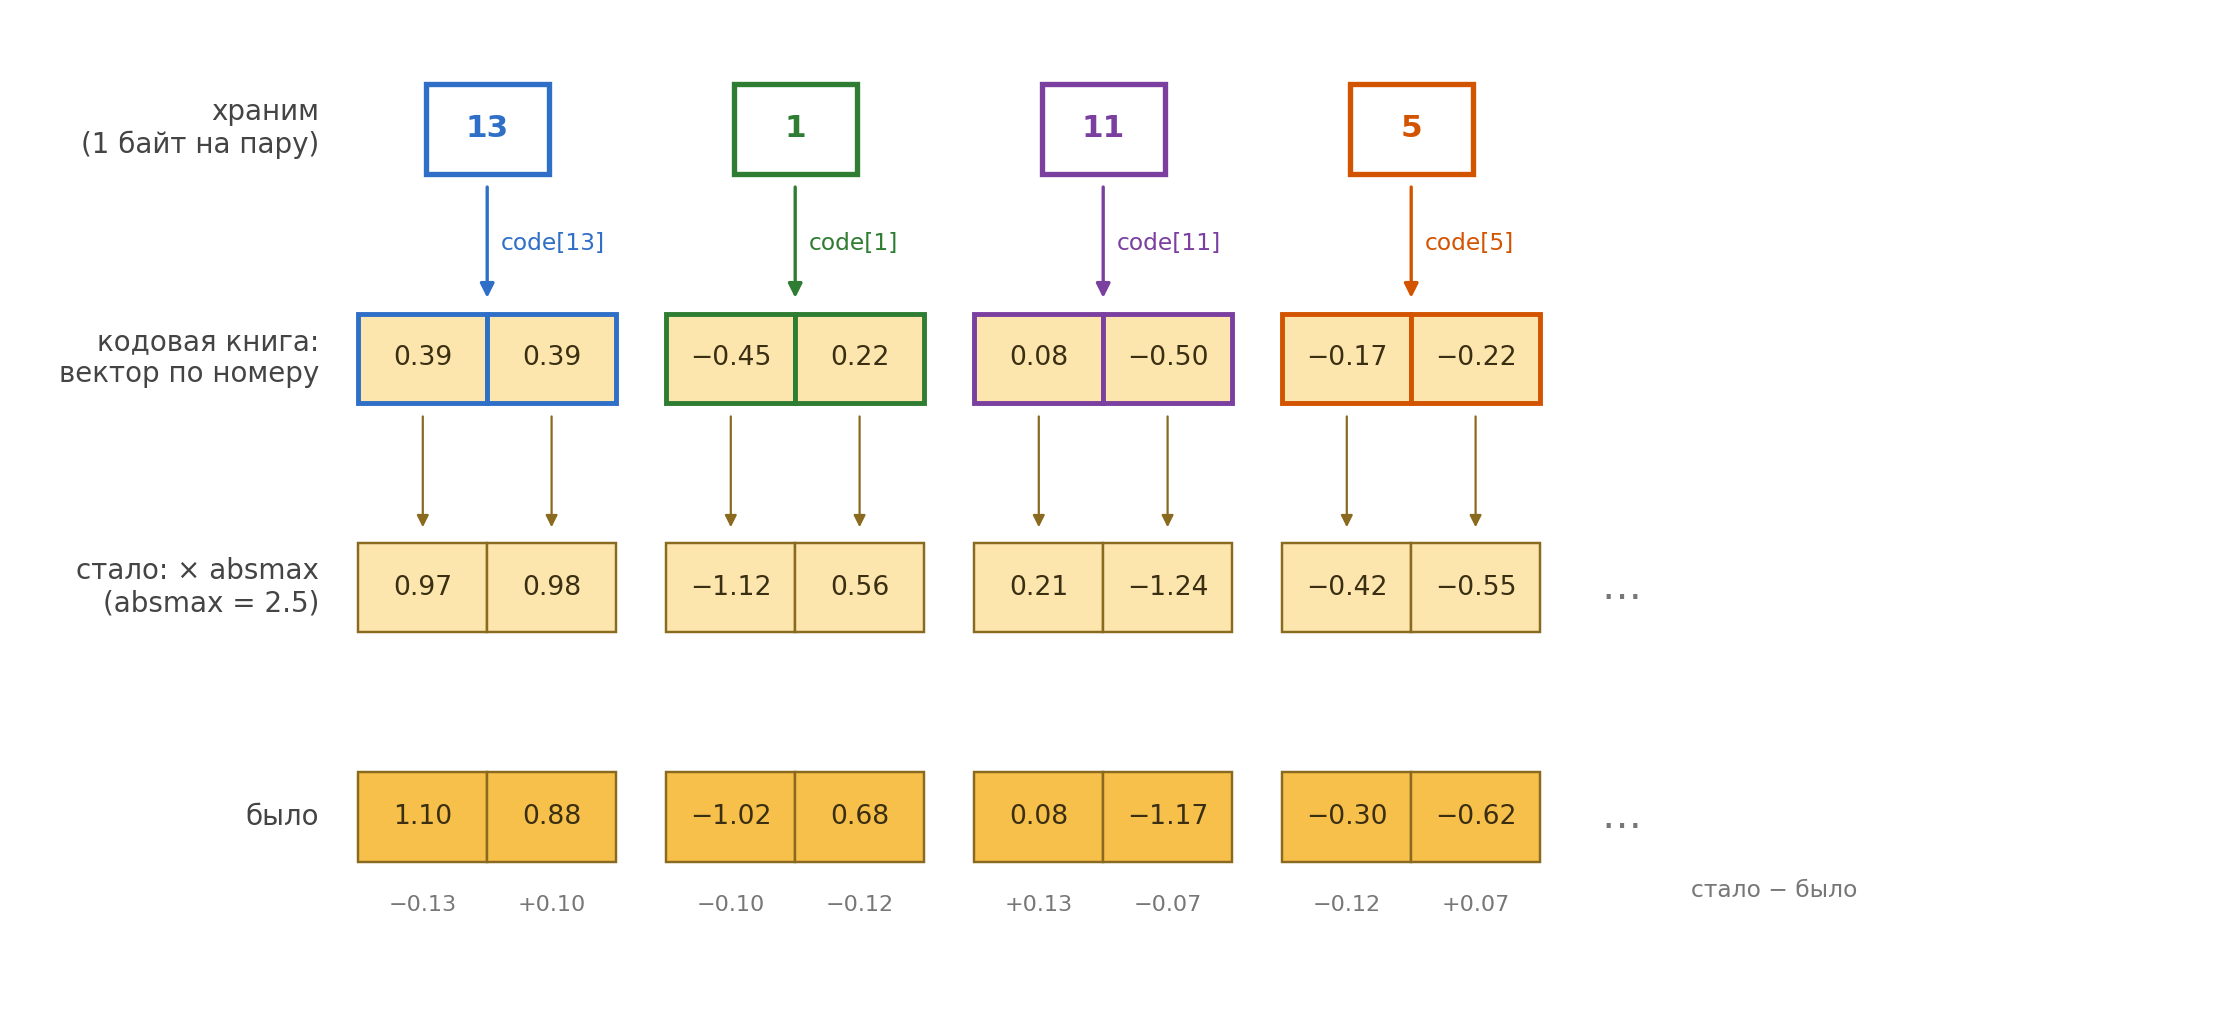

На этой идее построены методы сжатия LLM до 2 бит на вес AQLM, QuIP#

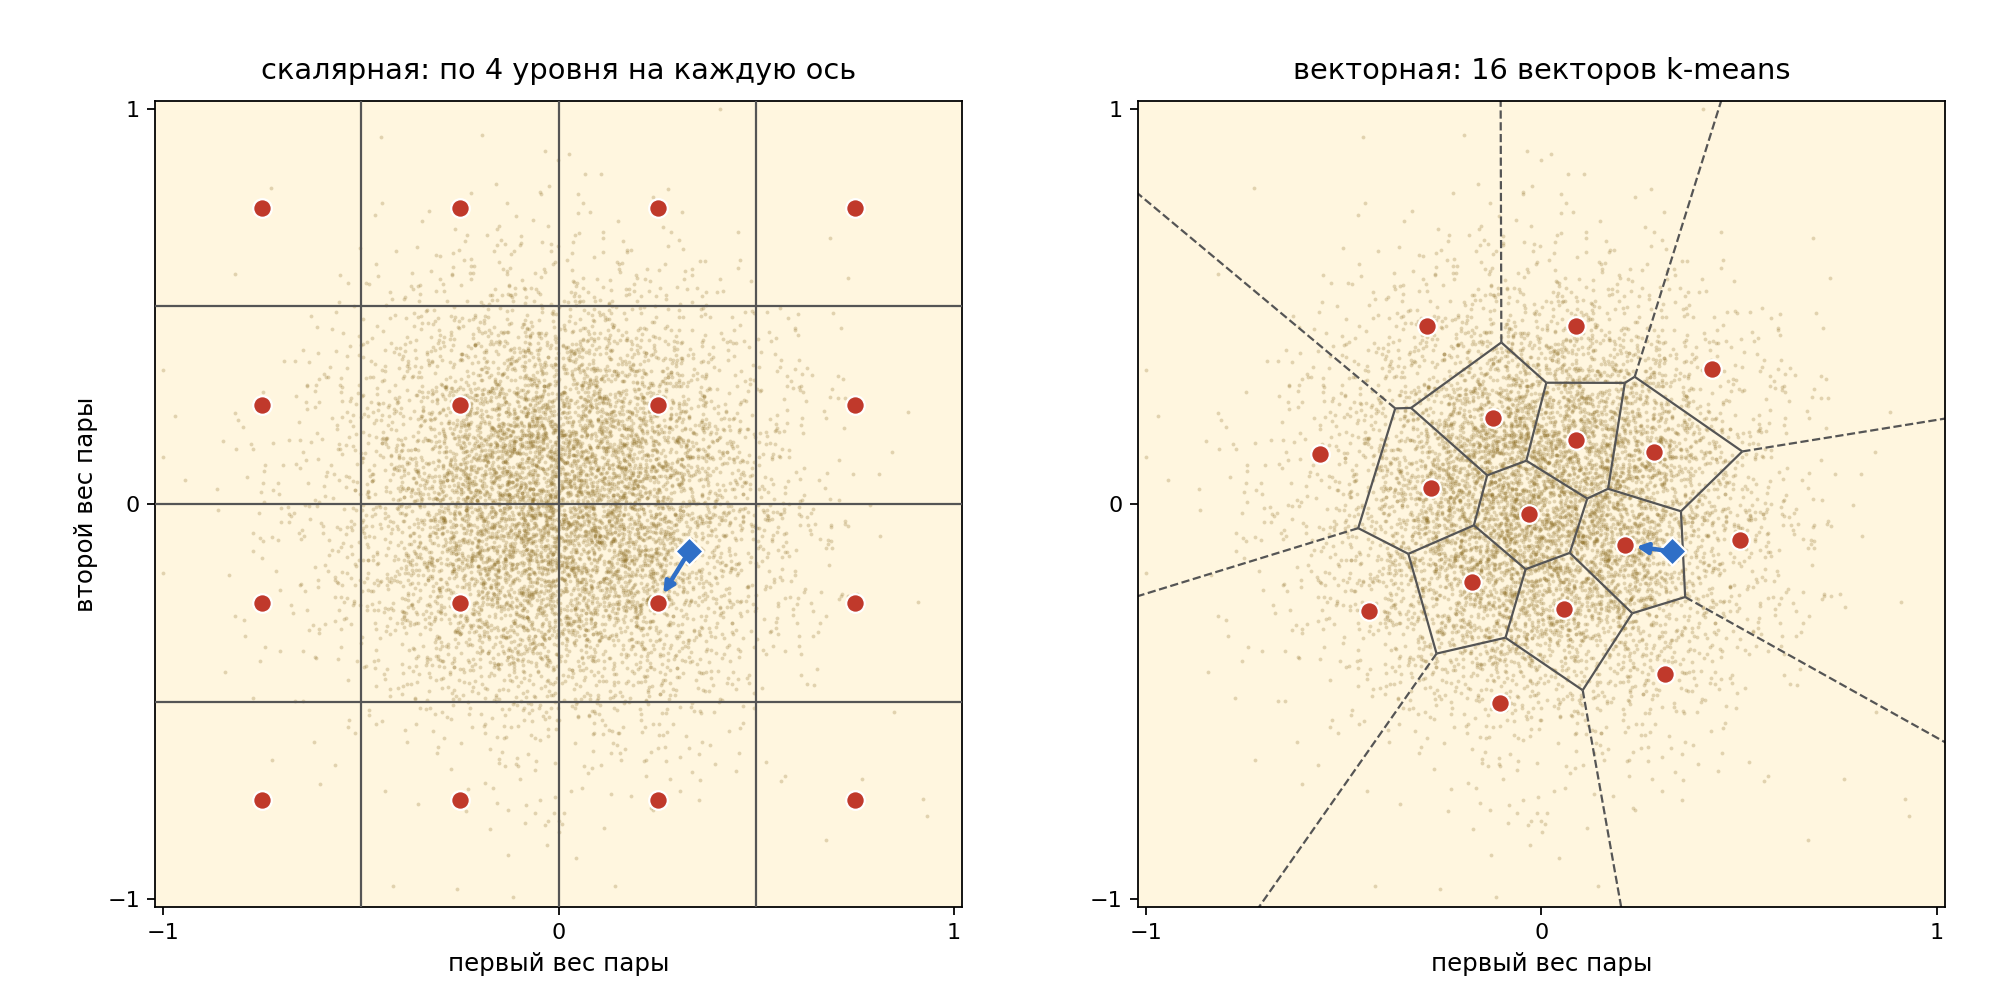

### Кодовая книга: k-means

In [25]:
def kmeans_codebook(x, d, n_codes=256, iters=25, sample=1 << 17):
    v = (x.float() / x.float().abs().amax(dim=1, keepdim=True)).reshape(-1, d)
    v = v[torch.randint(len(v), (sample,), device=x.device)]
    code = v[torch.randperm(sample, device=x.device)[:n_codes]].clone()      
    for _ in range(iters):
        idx = torch.cdist(v, code).argmin(dim=1)                            
        sums = torch.zeros_like(code).index_add_(0, idx, v)
        counts = torch.bincount(idx, minlength=n_codes)[:, None]
        code = torch.where(counts > 0, sums / counts.clamp_min(1), code)     
    return code.contiguous()


codebooks = {d: kmeans_codebook(W, d) for d in (2, 4)}


def torch_vq_quantize(x, code):
    d = code.shape[1]
    absmax = x.float().abs().amax(dim=1)
    v = (x.float() / absmax[:, None]).reshape(-1, d)
    q = torch.cat([torch.cdist(chunk, code).argmin(dim=1)
                   for chunk in v.split(1 << 20)])                          
    return q.to(torch.uint8).reshape(x.shape[0], -1), absmax


def torch_vq_dequantize(q, absmax, code):
    return (code[q.long()].reshape(q.shape[0], -1) * absmax[:, None]).half()

### Точность при тех же битах на вес

Сравним с линейной квантизацией по строкам с тем же числом бит на вес, симметричной (2.2) и несимметричной (2.3): 4 бита против $d = 2$ и 2 бита против $d = 4$, 8 бит — для ориентира.

In [26]:
def linear_roundtrip(x, bits):
    qmax = 2 ** (bits - 1) - 1
    absmax = x.float().abs().amax(dim=1, keepdim=True)
    return (torch.round(x.float() / absmax * qmax) / qmax * absmax).half()


def linear_roundtrip_asym(x, bits):
    qmax = 2 ** bits - 1
    xmin, xmax = x.float().amin(dim=1, keepdim=True), x.float().amax(dim=1, keepdim=True)
    return (torch.round((x.float() - xmin) / (xmax - xmin) * qmax) / qmax * (xmax - xmin) + xmin).half()


def compare_errors(w, books):
    rows = []
    for bits, d in [(4, 2), (2, 4)]:
        q, absmax = torch_vq_quantize(w, books[d])
        rows.append([bits, f"{rel_err(w, linear_roundtrip(w, bits)):.2e}", f"{rel_err(w, linear_roundtrip_asym(w, bits)):.2e}",
                     f"{rel_err(w, torch_vq_dequantize(q, absmax, books[d])):.2e}  (d = {d})"])
    print(tabulate(rows, headers=["бит на вес", "симметричная", "несимметричная", "векторная"], tablefmt="github", disable_numparse=True))


compare_errors(W, codebooks)

| бит на вес   | симметричная   | несимметричная   | векторная         |
|--------------|----------------|------------------|-------------------|
| 4            | 1.57e-01       | 1.40e-01         | 9.34e-02  (d = 2) |
| 2            | 9.09e-01       | 7.11e-01         | 3.16e-01  (d = 4) |


| бит на вес   | симметричная   | несимметричная   | векторная         |
|--------------|----------------|------------------|-------------------|
| 4            | 1.45e-01       | 1.27e-01         | 2.57e-02  (d = 2) |
| 2            | 8.74e-01       | 6.42e-01         | 3.87e-02  (d = 4) |


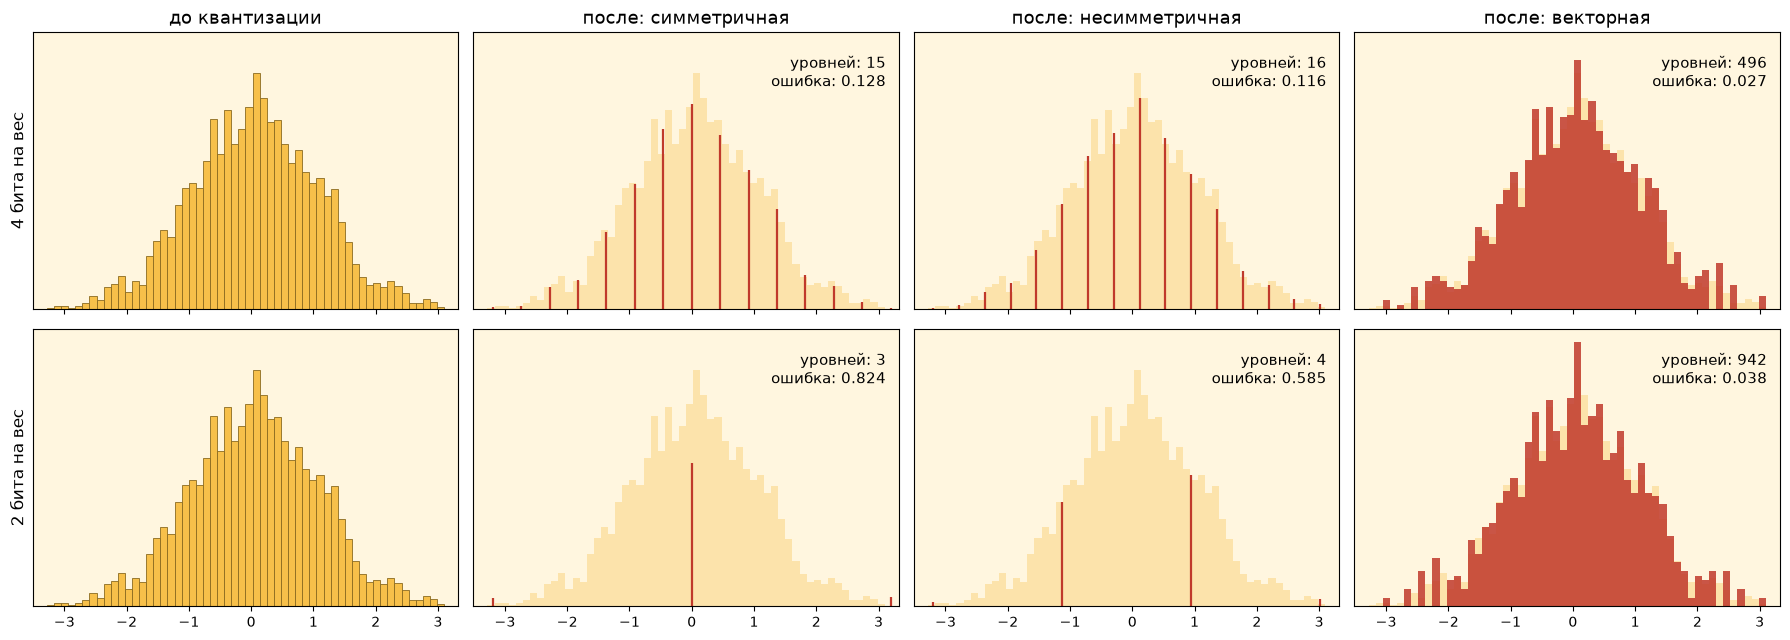

In [27]:
def plot_before_after(row, books):
    x = row.float().flatten().cpu().numpy()
    pad = 0.05 * (x.max() - x.min())
    bins = np.linspace(x.min() - pad, x.max() + pad, 61)
    cases = [(4, 2, "4 бита на вес"), (2, 4, "2 бита на вес")] 

    fig, axes = plt.subplots(len(cases), 4, figsize=(18, 6.5), sharex=True, sharey=True)
    for row_axes, (bits, d, label) in zip(axes, cases):
        row_axes[0].hist(x, bins=bins, density=True, color="#F7C04A", ec="#8A6A1F", lw=0.6)
        row_axes[0].set_ylabel(label, fontsize=12)

        for ax, row_hat in zip(row_axes[1:3], (linear_roundtrip(row, bits), linear_roundtrip_asym(row, bits))):
            ax.hist(x, bins=bins, density=True, color="#F7C04A", alpha=0.35)            # «до» для сравнения
            levels, counts = torch.unique(row_hat.float().flatten().cpu(), return_counts=True)
            step = levels.diff().min().item()                                          # палочки, как в 2.3
            ax.vlines(levels.numpy(), 0, counts.numpy() / (x.size * step), color="#C0392B", lw=1.6)
            ax.text(0.97, 0.92, f"уровней: {len(levels)}\nошибка: {rel_err(row, row_hat):.3f}",
                    transform=ax.transAxes, ha="right", va="top", fontsize=11)

        ax = row_axes[3]                                            
        q, absmax = torch_vq_quantize(row, books[d])
        row_hat = torch_vq_dequantize(q, absmax, books[d])
        ax.hist(x, bins=bins, density=True, color="#F7C04A", alpha=0.35)
        ax.hist(row_hat.float().flatten().cpu().numpy(), bins=bins, density=True, color="#C0392B", alpha=0.85)
        ax.text(0.97, 0.92, f"уровней: {len(torch.unique(row_hat))}\nошибка: {rel_err(row, row_hat):.3f}",
                transform=ax.transAxes, ha="right", va="top", fontsize=11)

        for ax in row_axes:
            ax.set_facecolor("#FFF6DF")
            ax.set_yticks([])

    axes[0, 0].set_xlim(bins[0], bins[-1])
    for ax, title in zip(axes[0], ("до квантизации", "после: симметричная", "после: несимметричная", "после: векторная")):
        ax.set_title(title, fontsize=13)
    fig.tight_layout()
    plt.show()


z = torch.randn(N, K // 4, 1, device=DEVICE)                          
W_corr = (z + 0.05 * torch.randn(N, K // 4, 4, device=DEVICE)).reshape(N, K).half()
codebooks_corr = {d: kmeans_codebook(W_corr, d) for d in (2, 4)}       

compare_errors(W_corr, codebooks_corr)
plot_before_after(W_corr[:1], codebooks_corr)                  

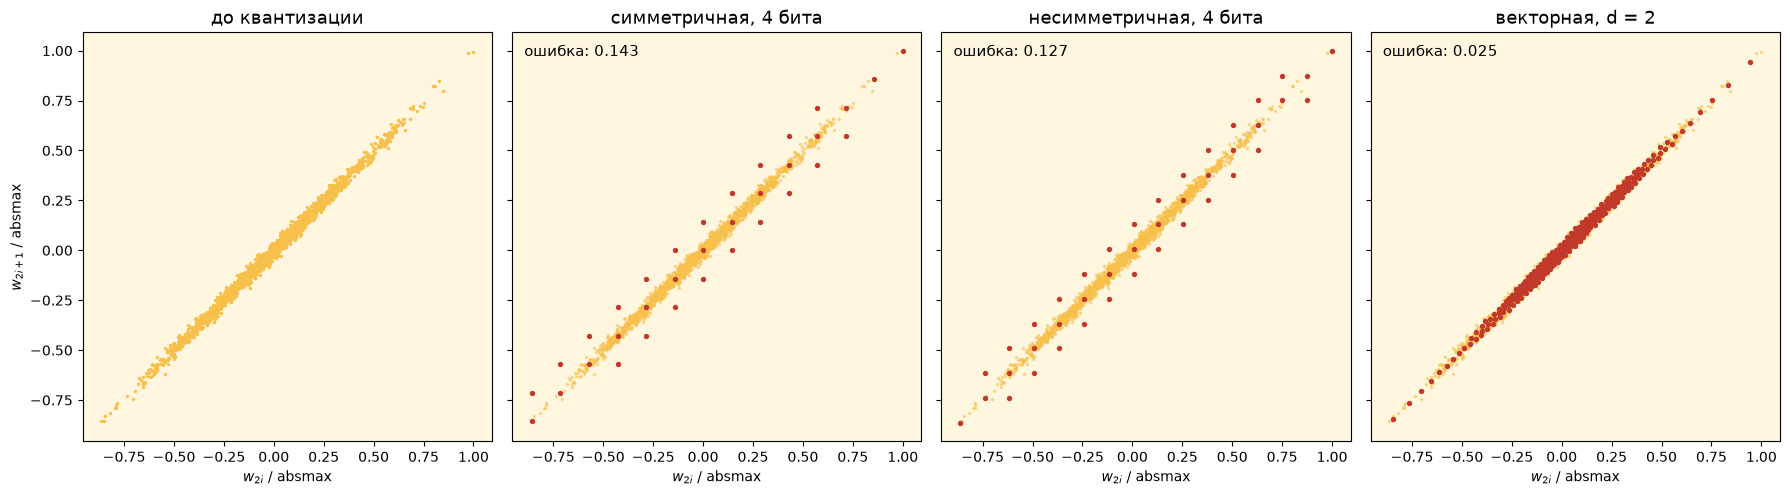

In [18]:
row = W_corr[:1]
absmax = row.float().abs().amax()
pts = (row.float() / absmax).reshape(-1, 2).cpu().numpy()
q, row_absmax = torch_vq_quantize(row, codebooks_corr[2])
variants = {
    "симметричная, 4 бита": linear_roundtrip(row, 4),
    "несимметричная, 4 бита": linear_roundtrip_asym(row, 4),
    "векторная, d = 2": torch_vq_dequantize(q, row_absmax, codebooks_corr[2]),
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8), sharex=True, sharey=True)
axes[0].scatter(pts[:, 0], pts[:, 1], s=2, color="#F7C04A")
axes[0].set_title("до квантизации", fontsize=13)
for ax, (title, row_hat) in zip(axes[1:], variants.items()):
    ax.scatter(pts[:, 0], pts[:, 1], s=2, color="#F7C04A", alpha=0.5)
    used = torch.unique((row_hat.float() / absmax).reshape(-1, 2), dim=0).cpu().numpy()   # куда попали пары
    ax.scatter(used[:, 0], used[:, 1], s=8, color="#C0392B")
    ax.text(0.03, 0.97, f"ошибка: {rel_err(row, row_hat):.3f}", transform=ax.transAxes, va="top", fontsize=11)
    ax.set_title(title, fontsize=13)
for ax in axes:
    ax.set_facecolor("#FFF6DF")
    ax.set_aspect("equal")
    ax.set_xlabel("$w_{2i}$ / absmax")
axes[0].set_ylabel("$w_{2i+1}$ / absmax")
fig.tight_layout()
plt.show()

In [19]:
bits_per_weight = lambda k, d: np.log2(k) / d      

for k, d in [(256, 2), (256, 4), (256, 3), (16, 3), (65536, 8), (1000, 2)]:
    print(f"книга {k:>5} векторов, d = {d}:  {bits_per_weight(k, d):.2f} бит на вес")

книга   256 векторов, d = 2:  4.00 бит на вес
книга   256 векторов, d = 4:  2.00 бит на вес
книга   256 векторов, d = 3:  2.67 бит на вес
книга    16 векторов, d = 3:  1.33 бит на вес
книга 65536 векторов, d = 8:  2.00 бит на вес
книга  1000 векторов, d = 2:  4.98 бит на вес


## 2.5. Умножение с квантованными весами

Цель этой части — проверить, может ли цепочка, в которой шагов больше, быть быстрее обычного fp16-умножения

1. **fp16:** `F.linear(x, W)`.
2. **INT8:** квантуем активации `x` по строкам → умножаем int8 × int8 → int32 на INT8-тензорных ядрах → деквантуем: `acc · s_x[m] · s_w[n] / 127²`. Веса квантованы заранее, как в 2.2.



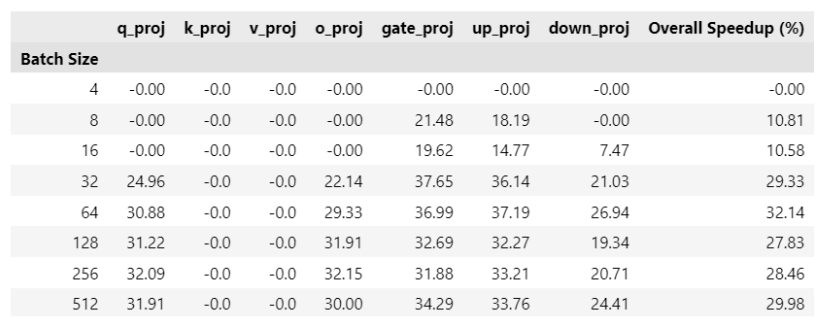

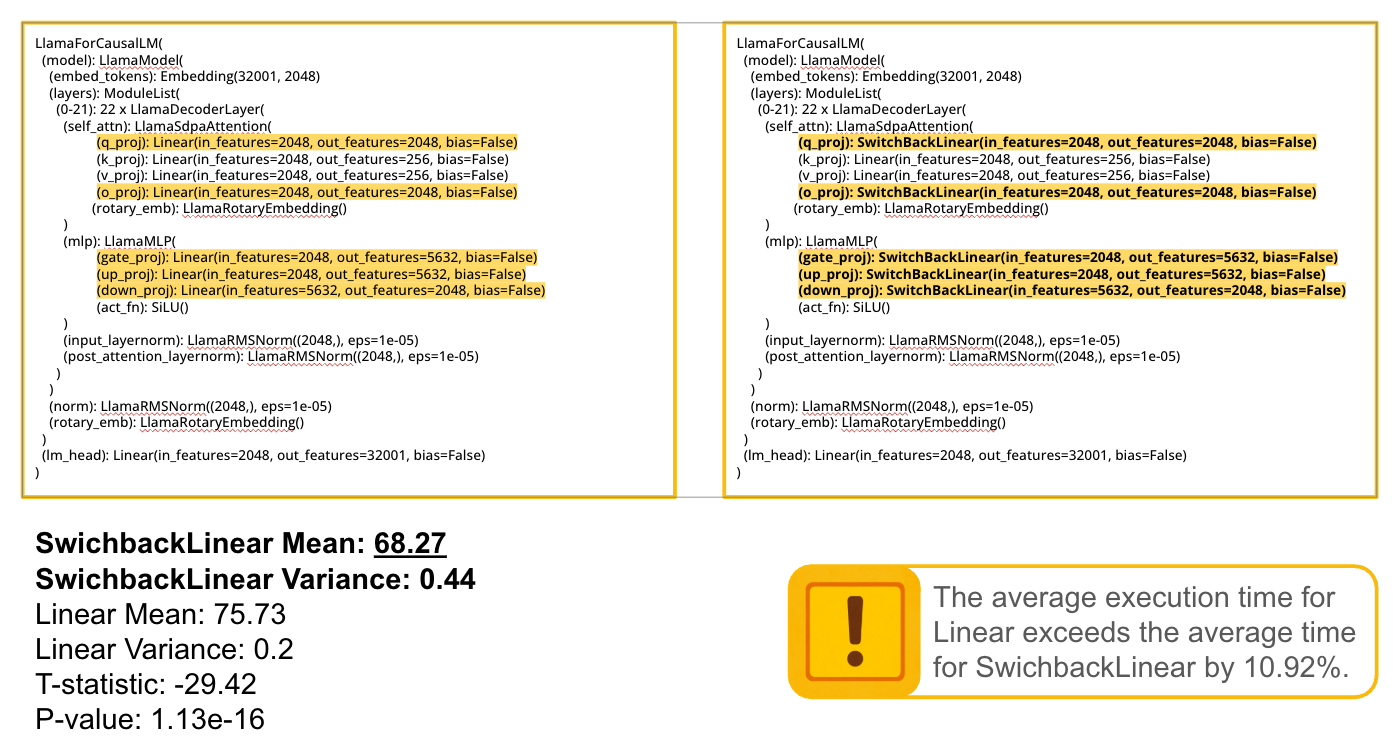

С `SwitchBackLinear` модель в среднем быстрее: `Linear` медленнее на 10.9%, и разница статистически значима (t-тест, p ≈ 10⁻¹⁶). Проверим то же на отдельном слое.